default 8 Å guard is conservative and follows earlier face-depth convention. 

## centre selection

| Centre | Radius (px) | Points | Occupied bins | In guard zones (%) | Continuous RMSE (Å) | P95 (Å) |
|---|---:|---:|---:|---:|---:|---:|
| (90,45) | 12 | 436 | 267 | 0.00 | 0.157 | 0.260 |
| (90,45) | 21 | 1877 | 973 | 19.39 | 0.785 | 1.348 |
| (90,45) | 25 | 3264 | 1489 | 23.99 | 1.592 | 2.793 |
| (89,37) | 15 | 864 | 473 | 0.00 | 0.797 | 1.380 |
| (89,37) | 18 | 1426 | 714 | 0.00 | 1.346 | 2.378 |
| (89,37) | 19 | 1697 | 810 | 0.00 | 1.599 | 2.821 |
| (89,37) | 20 | 2030 | 922 | 0.00 | 1.985 | 3.564 |
| (89,37) | 21 | 2339 | 1016 | 0.00 | 2.297 | 4.282 |
| (89,37) | 25 | 4748 | 1549 | 18.49 | 4.804 | 8.773 |


In [1]:
from pathlib import Path
import hashlib, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.spatial import cKDTree
from scipy.spatial.transform import Rotation
from scipy.optimize import least_squares
from scipy.ndimage import gaussian_filter
from scipy.stats import pearsonr, spearmanr
from IPython.display import display
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 115, 'font.size': 10})


In [ ]:
DATA_DIR = Path('.')  # Change to your folder in Colab or on your computer.
if not (DATA_DIR / 'nylon_planar_projection_points_reverse.csv').is_file() and (DATA_DIR / 'upload').is_dir():
    DATA_DIR = DATA_DIR / 'upload'
PLANE_CSV = DATA_DIR / 'nylon_planar_projection_points_reverse.csv'
COORD_TXT = DATA_DIR / 'NYL_newVer_rotY90resnum_bfactor_coord_list.txt'
PROJECTED_TXT = DATA_DIR / 'NYL_newVer_rotY90resnum_bfactor_projected_values.txt'
SHELL_PDB = None  # Set the exact full mapped-shell PDB path here.
FACE_MODE = "surfmap_roi"  # "surfmap_roi", "opposite_face", or "source_face".
OPPOSITE_ORIGIN_XYZ = None  # Optional known point at the opposite face centre, in Å.
OPPOSITE_DEPTH_A = None  # None: reuse the maximum source CSV depth.
GEOMETRY_TOL_A = 0.002
MAX_FULL_SHELL_ANGLE_ERROR_DEG = 0.05
if FACE_MODE not in {"surfmap_roi", "opposite_face", "source_face"}:
    raise ValueError("Unknown FACE_MODE.")
if SHELL_PDB is None:
    shell_candidates=list(DATA_DIR.glob('NYL_newVer_rotY90resnum_bfactor_mapped_shell.pdb'))
    if len(shell_candidates)==1:
        SHELL_PDB=shell_candidates[0]

INDEX_OFFSET = 1
MAP_SHAPE = (90, 180)  # numpy rows, columns; PNG width=180, height=90.
ROI_BASELINE_CENTER_COL_ROW = np.array([90., 45.])
ROI_CENTER_COL_ROW = ROI_BASELINE_CENTER_COL_ROW.copy()
ROI_CENTER_MODE = "max_clearance"  # "max_clearance" or "fixed".
ROI_CENTER_SEARCH_STEP = 1.  # Pixels; the default search covers the whole grid.
ROI_COMPARISON_RADII = [12., 15., 18., 19., 20., 21., 25., 30.]
ROI_RADIUS_PIXELS = 25.  # Baseline only; automatically replaced in surfmap_roi mode.
ROI_CANDIDATE_RADII = np.arange(5., 36., 1.)
ROI_EDGE_GUARD_A = 8.  # Conservative boundary zone, NOT a measured facet label.
ROI_SIDE_DEPTH_A = 8.
ROI_GUARD_SENSITIVITY_A = (2., 4., 6., 8.)
CENTRAL_RADII_A = [5, 10, 15, 20, 25, 30, 35, 40, 45]
DISTANCE_BANDS_A = [(0., .5), (.5, 1.), (1., 2.), (2., 5.), (5., 10.), (10., 15.)]
CHARGE_GRID_STEP_A = .5
SMOOTHING_SIGMA_A = [.5, 1., 2., 3., 5.]
SUPPORT_THRESHOLD = .02
SIGN_THRESHOLD = .05
CHARGE_NORMALIZATION = .78  # Shared supplied raw->normalized mapping, never per-image scaling
SAVE_TABLES = False
OUTPUT_DIR = Path('nylon_surfmap_roi_audit_outputs')
manifest = []
for path in [PLANE_CSV, COORD_TXT, PROJECTED_TXT]:
    if not path.is_file():
        raise FileNotFoundError(f'Update the input paths: {path}')
    manifest.append({'file': str(path), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
display(pd.DataFrame(manifest))


,file,sha256
0,nylon_planar_projection_points_reverse.csv,db4de8c0d3c4251e4f690e770ce4462a084d70100cf2c5...
1,NYL_newVer_rotY90resnum_bfactor_coord_list.txt,aa8832c166cd8c01dccde5f6e680a02147f22fdaf9be66...
2,NYL_newVer_rotY90resnum_bfactor_projected_valu...,7193f8fec9b2d42787361fefef5a37976c6f448b9b4270...


In [22]:
plane = pd.read_csv(PLANE_CSV)
coord = pd.read_csv(COORD_TXT, sep=r'\s+')
projected = pd.read_csv(PROJECTED_TXT, sep=r'\s+')
for table, required in [(plane, ['point_id','x','y','z','u_A','v_A','depth_A','charge_raw']),
                        (coord, ['absc','ord','value','index_sol']),
                        (projected, ['x_proj','y_proj','value'])]:
    if not set(required).issubset(table):
        raise ValueError(f'Missing columns: {set(required)-set(table)}')
    if not np.isfinite(table[required].to_numpy(dtype=float)).all():
        raise ValueError('Non-finite input values.')
for values in [plane.point_id, coord.index_sol]:
    if not np.array_equal(values.to_numpy(), values.to_numpy().astype(int)):
        raise ValueError('Point IDs must be integers.')
ids = plane.point_id.to_numpy(dtype=int)
if len(np.unique(ids)) != len(ids) or coord.index_sol.duplicated().any():
    raise ValueError('Duplicate point IDs: inspect seam copies explicitly before continuing.')
ordered = coord.sort_values('index_sol').reset_index(drop=True)
if not np.array_equal(ordered.index_sol.to_numpy(), np.arange(len(ordered))+INDEX_OFFSET):
    raise ValueError('The supplied complete-shell index convention is not satisfied.')
if len(projected) != len(ordered) or ids.min()<0 or ids.max()>=len(projected):
    raise ValueError('Inconsistent point counts or IDs.')
if not np.allclose(ordered.value, projected.value, atol=1e-10, rtol=0):
    raise ValueError('The two SURFMAP exports do not share the expected point order.')
selected = ordered.iloc[ids].reset_index(drop=True)
selected_raw = projected.iloc[ids].reset_index(drop=True)
q = plane.charge_raw.to_numpy(float)
if not np.allclose(selected.value, q, atol=1e-10, rtol=0):
    raise ValueError('Charge mismatch for paired point IDs.')
P = plane[['u_A','v_A']].to_numpy(float)
XYZ = plane[['x','y','z']].to_numpy(float)
S = selected_raw[['x_proj','y_proj']].to_numpy(float)
all_bins = ordered[['absc','ord']].to_numpy(float)
if not np.allclose(all_bins/2, np.round(all_bins/2)):
    raise ValueError('Unexpected bin spacing; adapt the grid convention explicitly.')
pixels_all = all_bins/2 - 1
pixels = pixels_all[ids]
if ((pixels_all<0).any() or (pixels_all[:,0]>=MAP_SHAPE[1]).any()
        or (pixels_all[:,1]>=MAP_SHAPE[0]).any()):
    raise ValueError('Grid indices fall outside MAP_SHAPE.')
B = selected[['absc','ord']].to_numpy(float)-np.array([181.,91.])
full_B = all_bins-np.array([181.,91.])
quantization_error = np.linalg.norm(projected[['x_proj','y_proj']].to_numpy()-full_B, axis=1)
if quantization_error.max()>np.sqrt(2)+.01:
    raise ValueError('Continuous coordinates and exported grid bins disagree.')
if SHELL_PDB is not None:
    xyz_shell=[]
    for line in Path(SHELL_PDB).read_text().splitlines():
        if line.startswith(('ATOM  ','HETATM')):
            xyz_shell.append([float(line[30:38]),float(line[38:46]),float(line[46:54])])
    xyz_shell=np.asarray(xyz_shell)
    if len(xyz_shell)!=len(ordered): raise ValueError('Shell point count mismatch.')
    xyz_error=np.linalg.norm(xyz_shell[ids]-XYZ,axis=1)
    if xyz_error.max()>.002: raise ValueError('Point IDs fail the direct shell XYZ check.')
    print('Maximum direct shell XYZ error (Å):',xyz_error.max())
print(f'CSV diagnostic: {len(P):,} points; full shell: {len(ordered):,}')
print('Maximum pointwise raw-charge difference:', np.max(np.abs(q-selected.value)))


Maximum direct shell XYZ error (Å): 0.0
CSV diagnostic: 6,280 points; full shell: 26,638
Maximum pointwise raw-charge difference: 0.0


In [4]:
D = np.column_stack([np.ones(len(P)), P, plane.depth_A.to_numpy()])
plane_basis = np.linalg.lstsq(D, XYZ, rcond=None)[0]
plane_reconstruction_error = np.linalg.norm(D@plane_basis-XYZ,axis=1)
if plane_reconstruction_error.max()>1e-5:
    raise ValueError('The supplied planar coordinates/depth do not form the expected rigid coordinate frame.')
if np.linalg.norm(plane_basis[1:]@plane_basis[1:].T-np.eye(3))>1e-5:
    raise ValueError('The planar/depth basis is not orthonormal.')
latitude = np.deg2rad(S[:,1])
if np.any(np.abs(latitude)>=np.pi/2): raise ValueError('Invalid sinusoidal latitude.')
longitude = np.deg2rad(S[:,0])/np.cos(latitude)
if np.max(np.abs(longitude))>np.pi+.001:
    raise ValueError('The standard sinusoidal longitude range is not satisfied.')
directions = np.column_stack([np.cos(latitude)*np.cos(longitude),
                              np.cos(latitude)*np.sin(longitude),np.sin(latitude)])
def sphere_residual(par):
    rays=XYZ-par[:3]
    rays=rays/np.maximum(np.linalg.norm(rays,axis=1)[:,None],1e-12)
    return (rays@Rotation.from_rotvec(par[3:]).as_matrix()-directions).ravel()
initial_center=XYZ.mean(0)-np.array([0.,0.,20.])
solutions=[least_squares(sphere_residual,np.r_[initial_center, rv],max_nfev=200)
           for rv in [np.zeros(3),[0,np.pi/2,0],[np.pi/2,0,0]]]
sphere_fit=min(solutions,key=lambda fit: np.sum(fit.fun**2))
projection_center=sphere_fit.x[:3]
rotation3=Rotation.from_rotvec(sphere_fit.x[3:]).as_matrix()
fitted_dirs=(XYZ-projection_center)
radius3=np.linalg.norm(fitted_dirs,axis=1)
fitted_dirs=fitted_dirs/radius3[:,None]@rotation3
angular_error=np.rad2deg(2*np.arcsin(np.clip(np.linalg.norm(fitted_dirs-directions,axis=1)/2,0,1)))
print('Angular consistency error, median / P95 / max (degrees):', np.quantile(angular_error,[.5,.95,1]))
if angular_error.max()>.05:
    raise ValueError('Failed geometric identity/projection check. Do not interpret the distortion metrics.')
print('Recovered projection centre (Å):', projection_center)
print('Radius min / median / max (Å):',np.quantile(radius3,[0,.5,1]))
print('3D reconstruction RMSE from (u,v,depth), Å:',np.sqrt(np.mean(plane_reconstruction_error**2)))
forward=(plane_basis[0]-projection_center)@rotation3
forward/=np.linalg.norm(forward)
north=plane_basis[2]@rotation3
north-=np.dot(north,forward)*forward
north/=np.linalg.norm(north)
east=np.cross(north,forward)
if east@(plane_basis[1]@rotation3)<0: east=-east
lat_control=np.arcsin(np.clip(directions@north,-1,1))
lon_control=np.arctan2(directions@east,directions@forward)
C=np.rad2deg(np.column_stack([lon_control*np.cos(lat_control),lat_control]))
variants={'SURFMAP continuous':S, 'SURFMAP binned':B, 'Re-centred control':C}


Angular consistency error, median / P95 / max (degrees): [0.00042934 0.00097488 0.0017879 ]
Recovered projection centre (Å): [15.68610322 33.75987287 20.48624713]
Radius min / median / max (Å): [21.21370553 36.89410546 53.51902372]
3D reconstruction RMSE from (u,v,depth), Å: 1.264926300797711e-14


,role,point_id,index_sol,column,row,x_proj,y_proj,raw_charge
0,Source face: nearest plane-origin point,17734,17735,96.0,1.0,12.074,-86.044,0.06
1,Unverified nearest antipodal direction,2904,2905,89.0,88.0,-0.411,86.166,0.06
2,Nearest continuous map origin,2767,2768,89.0,45.0,-0.112,1.176,0.36


Antipodal-candidate angular mismatch (degrees): 0.14510042088619482
This is not a verified physical opposite-face correspondence.


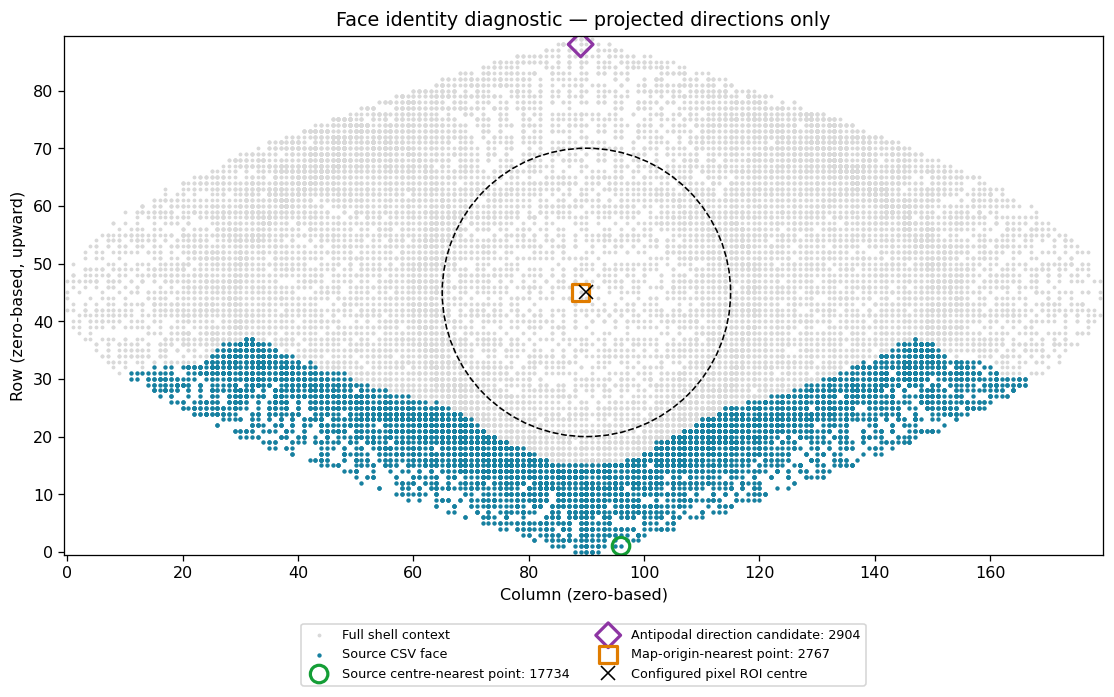

In [5]:
def inverse_sinusoidal(xy):
    lat=np.deg2rad(xy[:,1])
    if np.any(np.abs(lat)>=np.pi/2):
        raise ValueError('Latitude outside the supported open range (-90,90).')
    lon=np.deg2rad(xy[:,0])/np.cos(lat)
    if np.max(np.abs(lon))>np.pi+.001:
        raise ValueError('Invalid recovered longitude.')
    return np.column_stack([np.cos(lat)*np.cos(lon),np.cos(lat)*np.sin(lon),np.sin(lat)])
full_S=projected[['x_proj','y_proj']].to_numpy(float)
full_directions=inverse_sinusoidal(full_S)
source_centre_position=int(np.argmin(np.linalg.norm(P,axis=1)))
source_centre_id=int(ids[source_centre_position])
opposite_direction=-full_directions[source_centre_id]
angular_from_opposite=np.rad2deg(np.arccos(np.clip(full_directions@opposite_direction,-1,1)))
antipodal_candidate_id=int(np.argmin(angular_from_opposite))
map_origin_nearest_id=int(np.argmin(np.linalg.norm(full_S,axis=1)))
def point_record(label,point_id):
    return {'role':label,'point_id':point_id,'index_sol':point_id+INDEX_OFFSET,
            'column':pixels_all[point_id,0],'row':pixels_all[point_id,1],
            'x_proj':full_S[point_id,0],'y_proj':full_S[point_id,1],
            'raw_charge':float(ordered.value.iloc[point_id])}
direction_diagnostic=pd.DataFrame([
    point_record('Source face: nearest plane-origin point',source_centre_id),
    point_record('Unverified nearest antipodal direction',antipodal_candidate_id),
    point_record('Nearest continuous map origin',map_origin_nearest_id)])
display(direction_diagnostic)
print('Antipodal-candidate angular mismatch (degrees):', angular_from_opposite[antipodal_candidate_id])
print('This is not a verified physical opposite-face correspondence.')
fig,ax=plt.subplots(figsize=(11,6),layout='constrained')
ax.scatter(pixels_all[:,0],pixels_all[:,1],c='.85',s=2,label='Full shell context')
ax.scatter(pixels[:,0],pixels[:,1],c='#1680a0',s=3,label='Source CSV face')
for pid,marker,color,label in [(source_centre_id,'o','#149e36','Source centre-nearest point'),
                               (antipodal_candidate_id,'D','#8d35a3','Antipodal direction candidate'),
                               (map_origin_nearest_id,'s','#e07c00','Map-origin-nearest point')]:
    ax.scatter(*pixels_all[pid],s=120,marker=marker,facecolors='none',edgecolors=color,linewidths=2,label=f'{label}: {pid}')
ax.plot(*ROI_CENTER_COL_ROW,'kx',ms=9,label='Configured pixel ROI centre')
ax.add_patch(Circle(ROI_CENTER_COL_ROW,ROI_RADIUS_PIXELS,fill=False,color='k',ls='--'))
ax.set(xlabel='Column (zero-based)',ylabel='Row (zero-based, upward)',xlim=(-.5,179.5),ylim=(-.5,89.5),
       title='Face identity diagnostic — projected directions only')
ax.set_aspect('equal');ax.legend(loc='upper center',bbox_to_anchor=(.5,-.12),ncol=2,fontsize=8)
plt.show();plt.close(fig)


In [23]:
if SHELL_PDB is not None:
    reflected_target=2*projection_center-xyz_shell[source_centre_id]
    counterpart_distance,counterpart_id=cKDTree(xyz_shell).query(reflected_target)
    print('Nearest point to centre-inverted source point:',int(counterpart_id))
    print('Residual to the centre-inversion target (Å):',float(counterpart_distance))
    print('Actual candidate XYZ (Å):',xyz_shell[counterpart_id])


Nearest point to centre-inverted source point: 2904
Residual to the centre-inversion target (Å): 0.07624144257861887
Actual candidate XYZ (Å): [13.854 33.957 47.981]


In [7]:
if SHELL_PDB is not None:
    c=plane_basis[0];normal=-plane_basis[3]
    projected_plus=xyz_shell-((xyz_shell-c)@normal)[:,None]*normal
    projected_minus=xyz_shell-((xyz_shell-c)@(-normal))[:,None]*(-normal)
    print('Max change in orthogonal projected XYZ after normal sign flip (Å):',
          np.max(np.linalg.norm(projected_plus-projected_minus,axis=1)))
    del projected_plus,projected_minus


Max change in orthogonal projected XYZ after normal sign flip (Å): 0.0


In [8]:
def select_surfmap_roi_plane(full_xyz, pixel_col_row, continuous_xy,
                             projection_center, rotation3, source_basis,
                             roi_center=(90., 45.), candidate_radii=range(5, 36),
                             edge_guard_A=8., side_depth_A=8.,
                             sensitivity_guards_A=(2., 4., 6., 8.),
                             map_shape=(90, 180)):
    """Choose a circular SURFMAP ROI and orthogonally project its EXACT point IDs.

    The plane normal is the physical direction of native SURFMAP origin (0,0).
    Its origin is the intersection of the chosen ROI-centre ray with the outer
    support plane. Adjacent support slabs are conservative edge guards, not a
    mesh-based classification of actual facets. No charge enters ROI selection.
    This function uses the verified exported bin convention: two native angular
    units per pixel, with bin centres absc-181 and ord-91.
    """
    xyz=np.asarray(full_xyz,float);pix=np.asarray(pixel_col_row,float)
    raw=np.asarray(continuous_xy,float);center=np.asarray(roi_center,float)
    c3=np.asarray(projection_center,float);R=np.asarray(rotation3,float)
    source_basis=np.asarray(source_basis,float)
    if xyz.ndim!=2 or xyz.shape[1]!=3 or pix.shape!=(len(xyz),2) or raw.shape!=pix.shape:
        raise ValueError('XYZ, continuous coordinates and pixel rows must share point order.')
    if not all(np.isfinite(a).all() for a in [xyz,pix,raw,center,c3,R,source_basis]):
        raise ValueError('All geometry inputs must be finite.')
    if not np.allclose(R.T@R,np.eye(3),atol=1e-6):
        raise ValueError('rotation3 must be an orthogonal frame transform.')
    if edge_guard_A<=0 or side_depth_A<=0:
        raise ValueError('Use positive, explicitly chosen geometric guard depths.')
    unit=lambda a: a/np.linalg.norm(a)
    normal=unit(np.array([1.,0.,0.])@R.T)
    eu=np.array([0.,1.,0.])@R.T;eu=unit(eu-(eu@normal)*normal)
    ev=np.cross(normal,eu)
    level=float(np.max(xyz@normal))
    # The chosen integer pixel centre is not the continuous native origin.
    native_center=2*(center+1)-np.array([181.,91.])
    lat=np.deg2rad(native_center[1])
    if abs(lat)>=np.pi/2: raise ValueError('ROI centre is at/outside a sinusoidal pole.')
    lon=np.deg2rad(native_center[0])/np.cos(lat)
    ray=np.array([np.cos(lat)*np.cos(lon),np.cos(lat)*np.sin(lon),np.sin(lat)])@R.T
    if ray@normal<=1e-8: raise ValueError('ROI centre ray does not face the selected plane.')
    t=(level-c3@normal)/(ray@normal)
    if t<=0: raise ValueError('Support-plane intersection lies behind the projection centre.')
    origin=c3+t*ray
    uv_all=(xyz-origin)@np.stack([eu,ev],axis=1)
    side_depth=level-xyz@normal
    # Source/opposite and the two ends of the source frame bound the side patch.
    guard_normals={'source_face':unit(-source_basis[3]),
                   'opposite_face':unit(source_basis[3]),
                   'end_positive':unit(source_basis[2]),
                   'end_negative':unit(-source_basis[2])}
    depths={name:np.max(xyz@n)-xyz@n for name,n in guard_normals.items()}
    radial=np.linalg.norm(pix-center,axis=1)
    radii=np.unique(np.asarray(list(candidate_radii),float))
    if len(radii)==0 or np.any(~np.isfinite(radii)) or np.any(radii<=0):
        raise ValueError('Provide finite positive candidate ROI radii.')
    guards=np.unique(np.r_[sensitivity_guards_A,edge_guard_A])
    if np.any(guards<=0): raise ValueError('Guard depths must be positive.')
    rows=[]
    for guard in guards:
        excluded=(side_depth>side_depth_A+1e-9)
        for d in depths.values(): excluded|=(d<=guard+1e-9)
        for radius in radii:
            mask=radial<=radius
            n=int(mask.sum())
            inside_grid=(center[0]-radius>=0 and center[0]+radius<map_shape[1]
                         and center[1]-radius>=0 and center[1]+radius<map_shape[0])
            a=raw[mask];b=uv_all[mask]
            rmse=p95=scale=np.nan
            if n>=3 and np.sum((a-a.mean(0))**2)>0:
                aa=a-a.mean(0);bb=b-b.mean(0)
                U,_,Vt=np.linalg.svd(aa.T@bb);rot=U@Vt
                scale=np.sum((aa@rot)*bb)/np.sum(aa*aa)
                err=np.linalg.norm(scale*aa@rot-bb,axis=1)
                rmse=float(np.sqrt(np.mean(err**2)));p95=float(np.quantile(err,.95))
            row={'guard_A':float(guard),'radius_px':float(radius),'points':n,
                 'occupied_pixels':len(np.unique(pix[mask],axis=0)),
                 'excluded_points':int(np.sum(mask&excluded)),
                 'eligible':bool(inside_grid and n>=10 and not np.any(mask&excluded)),
                 'continuous_RMSE_A':rmse,'continuous_P95_A':p95,
                 'A_per_native_unit':scale}
            row.update({f'{k}_guard_points':int(np.sum(mask&(d<=guard+1e-9))) for k,d in depths.items()})
            rows.append(row)
    sweep=pd.DataFrame(rows)
    candidates=sweep[(sweep.guard_A==edge_guard_A)&sweep.eligible]
    if candidates.empty:
        raise ValueError('No pure circular ROI meets these guards. Inspect geometry; do not silently drop points.')
    radius=float(candidates.radius_px.max())
    chosen=radial<=radius;ids=np.flatnonzero(chosen)
    basis=np.vstack([origin,eu,ev,-normal])
    uv=uv_all[ids];depth=side_depth[ids]
    reconstructed=origin+uv@basis[1:3]+depth[:,None]*basis[3]
    if not np.allclose(reconstructed,xyz[ids],atol=1e-7,rtol=0):
        raise ValueError('Selected planar coordinates fail the 3D reconstruction check.')
    # A full circle is used: no selected bin may have an unselected contributor.
    all_in_bins=np.flatnonzero(np.linalg.norm(pix-center,axis=1)<=radius)
    if not np.array_equal(ids,all_in_bins): raise AssertionError('ROI point membership changed.')
    summary=sweep[sweep.eligible].sort_values('radius_px').groupby('guard_A').tail(1).sort_values('guard_A')
    return {'ids':ids,'uv':uv,'depth':depth,'basis':basis,'origin':origin,
            'outward_normal':normal,'radius_px':radius,'sweep':sweep,
            'sensitivity':summary,'side_depth_all':side_depth,'guard_depths':depths,
            'uv_all':uv_all,'roi_center_ray':ray,'native_center':native_center}


In [9]:
def search_roi_centers(full_xyz, pixels, projection_center, rotation3, source_basis,
                       guard_A=8., side_depth_A=8., baseline=(90.,45.),
                       map_shape=(90,180), radius_cap=35., step=1.):
    """Geometry-only search on a fixed plane; no charge or fit score is optimized.

    A circle may not include any exported bin with a forbidden point. Empty
    bins are not evidence of a surface; candidate centres are additionally
    restricted to the convex hull of occupied admissible bins. This hull is a
    search domain, not an exact physical facet or a contact-area estimate.
    Ties: maximum integer radius, then distance to the admissible pixel
    bounding-box centre, then baseline distance, row and column.
    """
    from scipy.spatial import ConvexHull
    xyz=np.asarray(full_xyz,float);pix=np.asarray(pixels,float)
    normal=np.array([1.,0.,0.])@rotation3.T
    depth=lambda n:np.max(xyz@n)-xyz@n
    safe=depth(normal)<=side_depth_A+1e-9
    for n in [-source_basis[3],source_basis[3],source_basis[2],-source_basis[2]]:
        n=n/np.linalg.norm(n);safe&=depth(n)>guard_A+1e-9
    good=np.unique(pix[safe],axis=0);bad=np.unique(pix[~safe],axis=0)
    # A bin with BOTH good and forbidden contributors is forbidden.
    good=good[cKDTree(bad).query(good)[0]>1e-9] if len(bad) else good
    if len(good)<3:raise ValueError('Too few fully admissible occupied bins.')
    hull=ConvexHull(good)
    cols,rows=np.meshgrid(np.arange(0,map_shape[1],step),np.arange(0,map_shape[0],step))
    centers=np.column_stack([cols.ravel(),rows.ravel()])
    centers=centers[np.all(centers@hull.equations[:,:2].T+hull.equations[:,2]<=1e-9,axis=1)]
    reference=(good.min(0)+good.max(0))/2
    def capacity(pts):
        clearance=cKDTree(bad).query(pts)[0] if len(bad) else np.full(len(pts),np.inf)
        edge=np.min(np.c_[pts[:,0],map_shape[1]-1-pts[:,0],pts[:,1],map_shape[0]-1-pts[:,1]],axis=1)
        # Inclusion uses distance <= r; equality to a forbidden point is rejected.
        radius=np.minimum(np.ceil(clearance-1e-9)-1,np.floor(edge+1e-9))
        return np.minimum(radius,radius_cap),clearance
    radius,clearance=capacity(centers)
    table=pd.DataFrame({'column':centers[:,0],'row':centers[:,1],
        'max_radius_px':radius,'nearest_forbidden_px':clearance,
        'bbox_center_distance':np.linalg.norm(centers-reference,axis=1),
        'baseline_distance':np.linalg.norm(centers-np.asarray(baseline),axis=1)})
    table=table.sort_values(['max_radius_px','bbox_center_distance','baseline_distance','row','column'],
                            ascending=[False,True,True,True,True]).reset_index(drop=True)
    best=table.iloc[0][['column','row']].to_numpy(float)
    # An approximate physical footprint centroid, based on the convex hull in Å.
    eu=np.array([0.,1.,0.])@rotation3.T;ev=np.cross(normal,eu)
    uv=xyz[safe]@np.stack([eu,ev],axis=1)
    vertices=uv[ConvexHull(uv).vertices];nxt=np.roll(vertices,-1,axis=0)
    cross=vertices[:,0]*nxt[:,1]-nxt[:,0]*vertices[:,1]
    centroid=((vertices+nxt)*cross[:,None]).sum(0)/(3*cross.sum())
    geometric_xyz=np.max(xyz@normal)*normal+centroid[0]*eu+centroid[1]*ev
    ray=(geometric_xyz-projection_center)@rotation3;ray/=np.linalg.norm(ray)
    lat=np.arcsin(np.clip(ray[2],-1,1));lon=np.arctan2(ray[1],ray[0])
    native=np.rad2deg([lon*np.cos(lat),lat])
    geometric_pixel=(native+np.array([181.,91.]))/2-1
    candidates={'Original integer centre':np.asarray(baseline,float),
                'Array geometric centre':np.array([(map_shape[1]-1)/2,(map_shape[0]-1)/2]),
                'Admissible pixel bbox centre':reference,
                'Admissible occupied-bin centroid':good.mean(0),
                'Projected physical hull centroid':geometric_pixel,
                'Maximum admissible circle':best}
    cand=[]
    for name,c in candidates.items():
        cap,clear=capacity(c[None,:]);r=float(cap[0])
        m=np.linalg.norm(pix-c,axis=1)<=r
        cand.append({'definition':name,'column':c[0],'row':c[1],'max_radius_px':r,
                     'points':int(m.sum()),'occupied_pixels':len(np.unique(pix[m],axis=0)),
                     'forbidden_points':int(np.sum(m&~safe))})
    return {'center':best,'radius':float(table.iloc[0].max_radius_px),'search':table,
            'candidates':pd.DataFrame(cand),'safe':safe,'good_pixels':good,
            'geometric_xyz':geometric_xyz,'geometric_pixel':geometric_pixel,
            'pixel_bbox_center':reference}


Full-shell angular error, median / P95 / max (degrees): [0.00041793 0.00092868 0.00201786]
Source selection reproduced exactly: 6280 point IDs
Recovered source-origin error (Å): 7.32410687763558e-14
Centre definitions and their largest admissible integer radius:


,definition,column,row,max_radius_px,points,occupied_pixels,forbidden_points
0,Original integer centre,90.00000,45.00000,12.0,436,267,0
1,Array geometric centre,89.50000,44.50000,13.0,542,332,0
2,Admissible pixel bbox centre,89.50000,37.50000,20.0,1996,920,0
3,Admissible occupied-bin centroid,89.83641,37.01187,20.0,2033,919,0
4,Projected physical hull centroid,89.12916,29.86306,14.0,1139,470,0
5,Maximum admissible circle,89.00000,37.00000,21.0,2339,1016,0


Chosen centre: [89. 37.] | Normal is unchanged; only the plane origin moves within the plane.
Largest eligible tested radius for each edge guard:


,guard_A,radius_px,points,occupied_pixels,excluded_points,eligible,continuous_RMSE_A,continuous_P95_A,A_per_native_unit,source_face_guard_points,opposite_face_guard_points,end_positive_guard_points,end_negative_guard_points
18,2.0,23.0,3433,1268,0,True,3.54151,6.56768,0.48686,0,0,0,0
48,4.0,22.0,2858,1144,0,True,2.87839,5.09494,0.46575,0,0,0,0
79,6.0,22.0,2858,1144,0,True,2.87839,5.09494,0.46575,0,0,0,0
109,8.0,21.0,2339,1016,0,True,2.29714,4.28211,0.44558,0,0,0,0


Default guard/radius: 8.0 Å / 21.0 pixels
Selected points: 2339 | Central SURFMAP ROI — identical point IDs
Plane origin XYZ (Å): [-4.22301891 34.11965086 15.15073229]
Outward normal XYZ: [-1.00000000e+00  1.41060601e-07 -4.95038035e-07]
Depth min / median / max (Å): [6.99980781e-06 8.82016452e-01 1.70002553e+00]
In-plane bounds (Å): [-19.09135244 -25.79873022] [19.06564769 15.05426714]


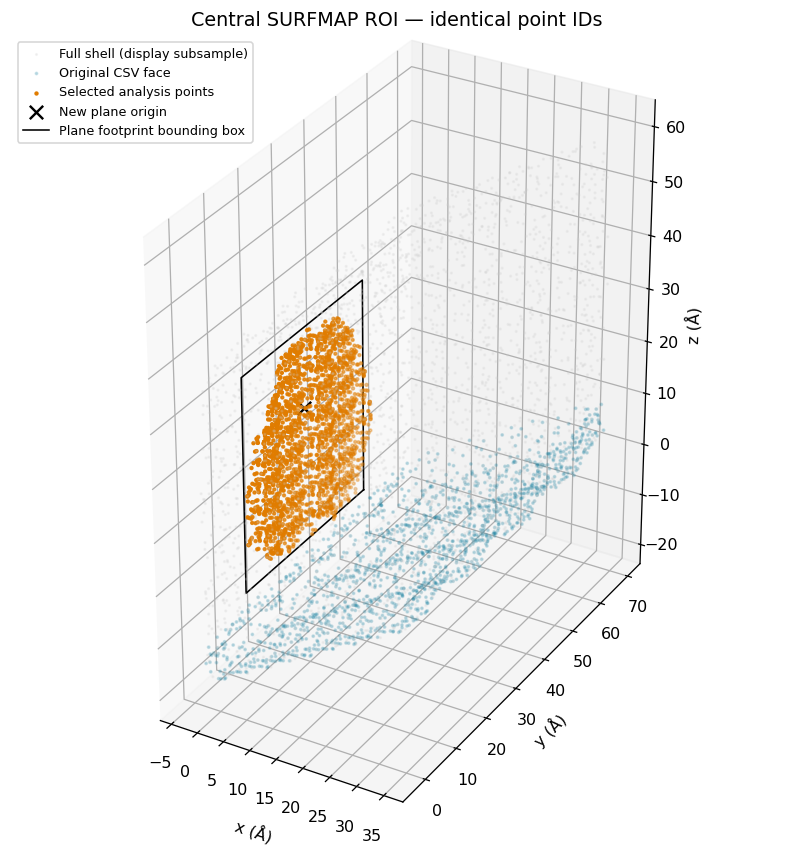

Requested face mode: surfmap_roi | Analysis status: Central SURFMAP ROI — identical point IDs


In [10]:
def select_parallel_face(full_xyz, outward_normal, in_plane_hint, depth_limit,
                         origin_override=None):
    """Select all shell points in an inward slab from the outer support plane."""
    xyz=np.asarray(full_xyz,float)
    normal=np.asarray(outward_normal,float);normal=normal/np.linalg.norm(normal)
    eu=np.asarray(in_plane_hint,float);eu=eu-(eu@normal)*normal;eu=eu/np.linalg.norm(eu)
    ev=np.cross(normal,eu)
    level=float(np.max(xyz@normal))
    depth=level-xyz@normal
    mask=(depth>=-1e-9)&(depth<=depth_limit+1e-9)
    ids=np.flatnonzero(mask)
    if len(ids)<10:raise ValueError('Too few points in the requested face slab.')
    # Reproduce the supplied CSV convention: projected bounding-box midpoint.
    umid=(np.min(xyz[mask]@eu)+np.max(xyz[mask]@eu))/2
    vmid=(np.min(xyz[mask]@ev)+np.max(xyz[mask]@ev))/2
    origin=level*normal+umid*eu+vmid*ev
    if origin_override is not None:
        candidate=np.asarray(origin_override,float)
        if candidate.shape!=(3,) or not np.isfinite(candidate).all():
            raise ValueError('The plane origin must be a finite XYZ vector.')
        if abs(candidate@normal-level)>.002:
            raise ValueError('The origin override is not on the selected outer support plane.')
        origin=candidate
    uv=(xyz[mask]-origin)@np.stack([eu,ev],axis=1)
    basis=np.vstack([origin,eu,ev,-normal])
    reconstructed=origin+uv@basis[1:3]+depth[mask,None]*basis[3]
    if np.max(np.linalg.norm(reconstructed-xyz[mask],axis=1))>1e-6:
        raise ValueError('The face frame fails 3D reconstruction.')
    return {'ids':ids,'uv':uv,'depth':depth[mask],'basis':basis,'origin':origin,'outward_normal':normal}

def select_opposite_face(full_xyz, source_basis, source_uv, depth_limit,
                         origin_override=None, tolerance=.002):
    # source_uv is retained for call compatibility; each full slab gets its own footprint.
    n=-source_basis[3]
    separation=float(np.ptp(np.asarray(full_xyz)@n))
    if separation<=depth_limit:
        raise ValueError('The requested slab spans the complete block thickness.')
    result=select_parallel_face(full_xyz,-n,source_basis[1],depth_limit,origin_override)
    result['separation_A']=separation
    return result

# Archive source-face data before changing the population.
source_plane=plane.copy();source_ids=ids.copy();source_basis=plane_basis.copy()
ANALYSIS_READY=(FACE_MODE=='source_face')
if FACE_MODE=='source_face':
    print('EXPLICIT SOURCE-FACE DIAGNOSTIC: this is not the opposite-face correction.')
    ANALYSIS_LABEL='Source CSV face — diagnostic only'
elif SHELL_PDB is None:
    ANALYSIS_LABEL='Opposite face — awaiting full mapped shell'
    print('OPPOSITE-FACE ANALYSIS NOT RUN: set SHELL_PDB to the exact complete mapped-shell PDB.')
    print('No radii or opposite-face XYZ are inferred from colours, charges or symmetry.')
else:
    # xyz_shell was read and checked against the source CSV in the loading cell.
    rays=xyz_shell-projection_center
    radii=np.linalg.norm(rays,axis=1)
    if np.any(radii<=1e-8): raise ValueError('A shell point coincides with the projection centre.')
    recovered=rays/radii[:,None]@rotation3
    full_angles=np.rad2deg(2*np.arcsin(np.clip(np.linalg.norm(recovered-full_directions,axis=1)/2,0,1)))
    print('Full-shell angular error, median / P95 / max (degrees):',np.quantile(full_angles,[.5,.95,1]))
    if full_angles.max()>MAX_FULL_SHELL_ANGLE_ERROR_DEG:
        raise ValueError('Full shell XYZ and SURFMAP exports are inconsistent; do not assign opposite-face IDs.')
    depth_limit=float(source_plane.depth_A.max()) if OPPOSITE_DEPTH_A is None else float(OPPOSITE_DEPTH_A)
    if not np.isfinite(depth_limit) or depth_limit<=0: raise ValueError('Invalid opposite depth limit.')
    source_check=select_parallel_face(xyz_shell,-source_basis[3],source_basis[1],float(source_plane.depth_A.max()))
    if not np.array_equal(np.sort(source_check['ids']),np.sort(source_ids)):
        raise ValueError('The support-plane slab rule does not reproduce the source CSV; supply the original selection code.')
    print('Source selection reproduced exactly:',len(source_check['ids']),'point IDs')
    print('Recovered source-origin error (Å):',np.linalg.norm(source_check['origin']-source_basis[0]))
    if FACE_MODE=='surfmap_roi':
        center_search=search_roi_centers(xyz_shell,pixels_all,projection_center,rotation3,source_basis,
            guard_A=ROI_EDGE_GUARD_A,side_depth_A=ROI_SIDE_DEPTH_A,
            baseline=ROI_BASELINE_CENTER_COL_ROW,map_shape=MAP_SHAPE,
            radius_cap=float(ROI_CANDIDATE_RADII.max()),step=ROI_CENTER_SEARCH_STEP)
        center_comparison_table=center_search['candidates']
        print('Centre definitions and their largest admissible integer radius:')
        display(center_comparison_table.round(5))
        if ROI_CENTER_MODE=='max_clearance': ROI_CENTER_COL_ROW=center_search['center'].copy()
        elif ROI_CENTER_MODE!='fixed': raise ValueError('Unknown ROI_CENTER_MODE.')
        print('Chosen centre:',ROI_CENTER_COL_ROW,'| Normal is unchanged; only the plane origin moves within the plane.')
        roi_selection=select_surfmap_roi_plane(
            xyz_shell,pixels_all,full_S,projection_center,rotation3,source_basis,
            roi_center=ROI_CENTER_COL_ROW,candidate_radii=ROI_CANDIDATE_RADII,
            edge_guard_A=ROI_EDGE_GUARD_A,side_depth_A=ROI_SIDE_DEPTH_A,
            sensitivity_guards_A=ROI_GUARD_SENSITIVITY_A,map_shape=MAP_SHAPE)
        selection=roi_selection
        ROI_RADIUS_PIXELS=selection['radius_px']
        roi_sweep_table=selection['sweep'];roi_sensitivity_table=selection['sensitivity']
        print('Largest eligible tested radius for each edge guard:')
        display(roi_sensitivity_table.round(5))
        print('Default guard/radius:',ROI_EDGE_GUARD_A,'Å /',ROI_RADIUS_PIXELS,'pixels')
    else:
        selection=select_opposite_face(xyz_shell,source_basis,source_plane[['u_A','v_A']].to_numpy(),
                                      depth_limit,OPPOSITE_ORIGIN_XYZ,GEOMETRY_TOL_A)
        opposite=selection  # Backward-compatible name for the opposite-face overview.
    ids=selection['ids'];P=selection['uv'];XYZ=xyz_shell[ids];plane_basis=selection['basis']
    if FACE_MODE=='opposite_face' and len(np.intersect1d(source_ids,ids)):
        raise ValueError('Opposite and source populations overlap; inspect face selection.')
    selected=ordered.iloc[ids].reset_index(drop=True)
    selected_raw=projected.iloc[ids].reset_index(drop=True)
    q=selected.value.to_numpy(float)
    plane=pd.DataFrame({'point_id':ids,'x':XYZ[:,0],'y':XYZ[:,1],'z':XYZ[:,2],
        'u_A':P[:,0],'v_A':P[:,1],'depth_A':selection['depth'],
        'charge_raw':q,'charge_normalized':q/CHARGE_NORMALIZATION})
    S=selected_raw[['x_proj','y_proj']].to_numpy(float)
    pixels=pixels_all[ids]
    B=selected[['absc','ord']].to_numpy(float)-np.array([181.,91.])
    latitude=np.deg2rad(S[:,1]);longitude=np.deg2rad(S[:,0])/np.cos(latitude)
    directions=full_directions[ids]
    forward=(plane_basis[0]-projection_center)@rotation3;forward/=np.linalg.norm(forward)
    north=plane_basis[2]@rotation3;north-=np.dot(north,forward)*forward;north/=np.linalg.norm(north)
    east=np.cross(north,forward)
    if east@(plane_basis[1]@rotation3)<0: east=-east
    lat_control=np.arcsin(np.clip(directions@north,-1,1))
    lon_control=np.arctan2(directions@east,directions@forward)
    C=np.rad2deg(np.column_stack([lon_control*np.cos(lat_control),lat_control]))
    variants={'SURFMAP continuous':S,'SURFMAP binned':B,'Re-centred control':C}
    ANALYSIS_READY=True
    ANALYSIS_LABEL='Central SURFMAP ROI — identical point IDs' if FACE_MODE=='surfmap_roi' else 'Measured opposite face'
    print('Selected points:',len(ids),'|',ANALYSIS_LABEL)
    print('Plane origin XYZ (Å):',selection['origin'])
    print('Outward normal XYZ:',selection['outward_normal'])
    print('Depth min / median / max (Å):',np.quantile(selection['depth'],[0,.5,1]))
    print('In-plane bounds (Å):',P.min(0),P.max(0))
    fig=plt.figure(figsize=(9,7),layout='constrained');ax=fig.add_subplot(111,projection='3d')
    ax.scatter(*xyz_shell[::10].T,s=1,c='.8',alpha=.2,label='Full shell (display subsample)')
    ax.scatter(*source_plane[['x','y','z']].to_numpy()[::4].T,s=2,c='#1680a0',alpha=.2,label='Original CSV face')
    ax.scatter(*XYZ.T,s=3,c='#e07c00',label='Selected analysis points')
    ax.scatter(*plane_basis[0],s=70,c='k',marker='x',label='New plane origin')
    corners=plane_basis[0]+np.array([[P[:,0].min(),P[:,1].min()], [P[:,0].max(),P[:,1].min()],
              [P[:,0].max(),P[:,1].max()], [P[:,0].min(),P[:,1].max()],
              [P[:,0].min(),P[:,1].min()]])@plane_basis[1:3]
    ax.plot(*corners.T,color='k',lw=1,label='Plane footprint bounding box')
    ax.set(xlabel='x (Å)',ylabel='y (Å)',zlabel='z (Å)',title=ANALYSIS_LABEL)
    ax.set_box_aspect(np.maximum(np.ptp(xyz_shell,axis=0),1e-6));ax.legend(fontsize=8)
    plt.show();plt.close(fig)
    shell_path=Path(SHELL_PDB)
    manifest.append({'file':str(shell_path),'sha256':hashlib.sha256(shell_path.read_bytes()).hexdigest()})
print('Requested face mode:',FACE_MODE,'| Analysis status:',ANALYSIS_LABEL)


Complete radius sweep for the default guard (counts are shell points, not physical area):


,guard_A,radius_px,points,occupied_pixels,excluded_points,eligible,continuous_RMSE_A,continuous_P95_A,A_per_native_unit,source_face_guard_points,opposite_face_guard_points,end_positive_guard_points,end_negative_guard_points
93,8.0,5.0,83,47,0,True,0.10894,0.18827,0.34832,0,0,0,0
94,8.0,6.0,111,67,0,True,0.12269,0.20481,0.35031,0,0,0,0
95,8.0,7.0,150,92,0,True,0.13994,0.22428,0.35060,0,0,0,0
96,8.0,8.0,193,119,0,True,0.18043,0.28245,0.35359,0,0,0,0
97,8.0,9.0,258,154,0,True,0.25324,0.52607,0.35843,0,0,0,0
98,8.0,10.0,331,192,0,True,0.33336,0.60386,0.36385,0,0,0,0
99,8.0,11.0,419,236,0,True,0.37942,0.66526,0.36618,0,0,0,0
100,8.0,12.0,489,277,0,True,0.43445,0.77600,0.36936,0,0,0,0
101,8.0,13.0,609,346,0,True,0.54624,0.96673,0.37425,0,0,0,0
102,8.0,14.0,732,406,0,True,0.64777,1.19116,0.38023,0,0,0,0


Nominal ROI pixels / occupied exported bins / empty exported bins: 1373 1016 357
No-sample cells remain missing; they must not be assigned neutral charge zero.


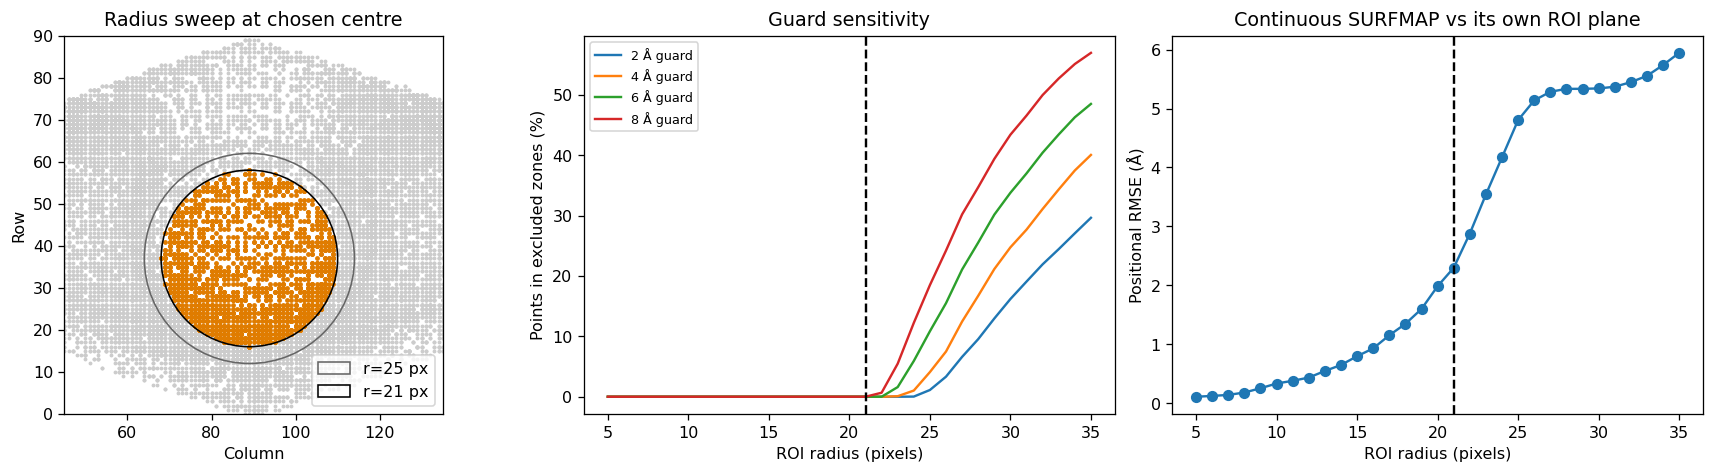

Selected planar points (first 10 rows):


,point_id,x,y,z,u_A,v_A,depth_A,charge_raw,charge_normalized,proj_x,proj_y,proj_z,SURFMAP_column,SURFMAP_row,radial_distance_A,signed_contact_distance_A
0,662,-3.139,24.264,27.027,9.85565,11.87626,1.08403,0.36,0.46154,-4.22303,24.264,27.027,102,53,15.43307,-1.08403
1,684,-3.421,25.278,27.583,8.84165,12.43226,0.80203,0.36,0.46154,-4.22303,25.278,27.583,101,54,15.25569,-0.80203
2,689,-3.523,26.236,28.610,7.88365,13.45927,0.70003,0.10,0.12821,-4.22303,26.236,28.610,99,55,15.59820,-0.70003
3,936,-3.370,17.906,17.710,16.21365,2.55926,0.85302,-0.60,-0.76923,-4.22302,17.906,17.710,109,41,16.41439,-0.85302
4,937,-3.101,17.977,18.054,16.14265,2.90326,1.12202,-0.60,-0.76923,-4.22302,17.977,18.054,109,42,16.40165,-1.12202
5,938,-2.739,19.268,18.335,14.85165,3.18426,1.48402,0.04,0.05128,-4.22302,19.268,18.335,109,42,15.18918,-1.48402
6,939,-2.586,19.135,18.839,14.98465,3.68826,1.63702,0.04,0.05128,-4.22302,19.135,18.839,109,42,15.43188,-1.63702
7,942,-2.572,19.693,19.052,14.42665,3.90126,1.65102,0.04,0.05128,-4.22302,19.693,19.052,108,43,14.94484,-1.65102
8,944,-2.616,20.354,20.283,13.76565,5.13226,1.60702,0.01,0.01282,-4.22302,20.354,20.283,108,44,14.69127,-1.60702
9,945,-2.742,20.453,21.137,13.66665,5.98626,1.48102,0.01,0.01282,-4.22302,20.453,21.137,107,45,14.92021,-1.48102


In [11]:
if ANALYSIS_READY and FACE_MODE=='surfmap_roi':
    default_sweep=roi_sweep_table[roi_sweep_table.guard_A==ROI_EDGE_GUARD_A]
    print('Complete radius sweep for the default guard (counts are shell points, not physical area):')
    display(default_sweep.round(5))
    yy,xx=np.indices(MAP_SHAPE)
    roi_pixel_mask=np.hypot(xx-ROI_CENTER_COL_ROW[0],yy-ROI_CENTER_COL_ROW[1])<=ROI_RADIUS_PIXELS
    occupied=len(np.unique(pixels,axis=0))
    print('Nominal ROI pixels / occupied exported bins / empty exported bins:',
          int(roi_pixel_mask.sum()),occupied,int(roi_pixel_mask.sum())-occupied)
    print('No-sample cells remain missing; they must not be assigned neutral charge zero.')
    fig,axs=plt.subplots(1,3,figsize=(15,4),layout='constrained')
    axs[0].scatter(*pixels_all.T,s=2,c='.8')
    axs[0].scatter(*pixels.T,s=4,c='#e07c00')
    for r,col in [(25.,'.4'),(ROI_RADIUS_PIXELS,'black')]:
        axs[0].add_patch(Circle(ROI_CENTER_COL_ROW,r,fill=False,color=col,label=f'r={r:g} px'))
    axs[0].set(xlim=(45,135),ylim=(0,90),xlabel='Column',ylabel='Row',title='Radius sweep at chosen centre');axs[0].set_aspect('equal');axs[0].legend()
    for guard,g in roi_sweep_table.groupby('guard_A'):
        axs[1].plot(g.radius_px,100*g.excluded_points/g.points,label=f'{guard:g} Å guard')
    axs[1].axvline(ROI_RADIUS_PIXELS,c='k',ls='--')
    axs[1].set(xlabel='ROI radius (pixels)',ylabel='Points in excluded zones (%)',title='Guard sensitivity');axs[1].legend(fontsize=8)
    axs[2].plot(default_sweep.radius_px,default_sweep.continuous_RMSE_A,'o-')
    axs[2].axvline(ROI_RADIUS_PIXELS,c='k',ls='--')
    axs[2].set(xlabel='ROI radius (pixels)',ylabel='Positional RMSE (Å)',title='Continuous SURFMAP vs its own ROI plane')
    plt.show();plt.close(fig)

    # This table can replace the original planar CSV in the downstream workflow.
    # Keep the exact selected IDs; do not select an independent physical circle.
    selected_roi_points=plane.copy()
    projected_xyz=XYZ+plane.depth_A.to_numpy()[:,None]*selection['outward_normal']
    for j,axis in enumerate('xyz'):selected_roi_points[f'proj_{axis}']=projected_xyz[:,j]
    selected_roi_points['SURFMAP_column']=pixels[:,0].astype(int)
    selected_roi_points['SURFMAP_row']=pixels[:,1].astype(int)
    selected_roi_points['radial_distance_A']=np.linalg.norm(P,axis=1)
    selected_roi_points['signed_contact_distance_A']=-plane.depth_A.to_numpy()
    print('Selected planar points (first 10 rows):');display(selected_roi_points.head(10).round(5))
    if SAVE_TABLES:
        OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
        selected_roi_points.to_csv(OUTPUT_DIR/'nylon_planar_projection_SURFMAP_ROI.csv',index=False)
        roi_sweep_table.to_csv(OUTPUT_DIR/'roi_radius_sweep.csv',index=False)
        np.savez_compressed(OUTPUT_DIR/'nylon_SURFMAP_ROI_geometry.npz',point_id=ids,
            xyz_A=XYZ,uv_A=P,depth_A=plane.depth_A.to_numpy(),charge_raw=q,
            plane_basis=plane_basis,surfmap_pixel_col_row=pixels,roi_pixel_mask=roi_pixel_mask,
            roi_radius_pixels=ROI_RADIUS_PIXELS,edge_guard_A=ROI_EDGE_GUARD_A)


Analysis population: Central SURFMAP ROI — identical point IDs | n = 2339


,point_id,distance_to_plane_origin_A,SURFMAP_column,SURFMAP_row,x_proj,y_proj
0,4012,0.396858,89.0,37.0,-1.66,-14.666


Conditional ROI at (89.0, 37.0), radius 21 pixels:
  selected-face points inside: 2339 / 2339 (100.00%)
  selected-face fraction of all shell points in this ROI: 100.00%
This diagnoses these exports; it does not establish the orientation of other saved PNG/NPY runs.


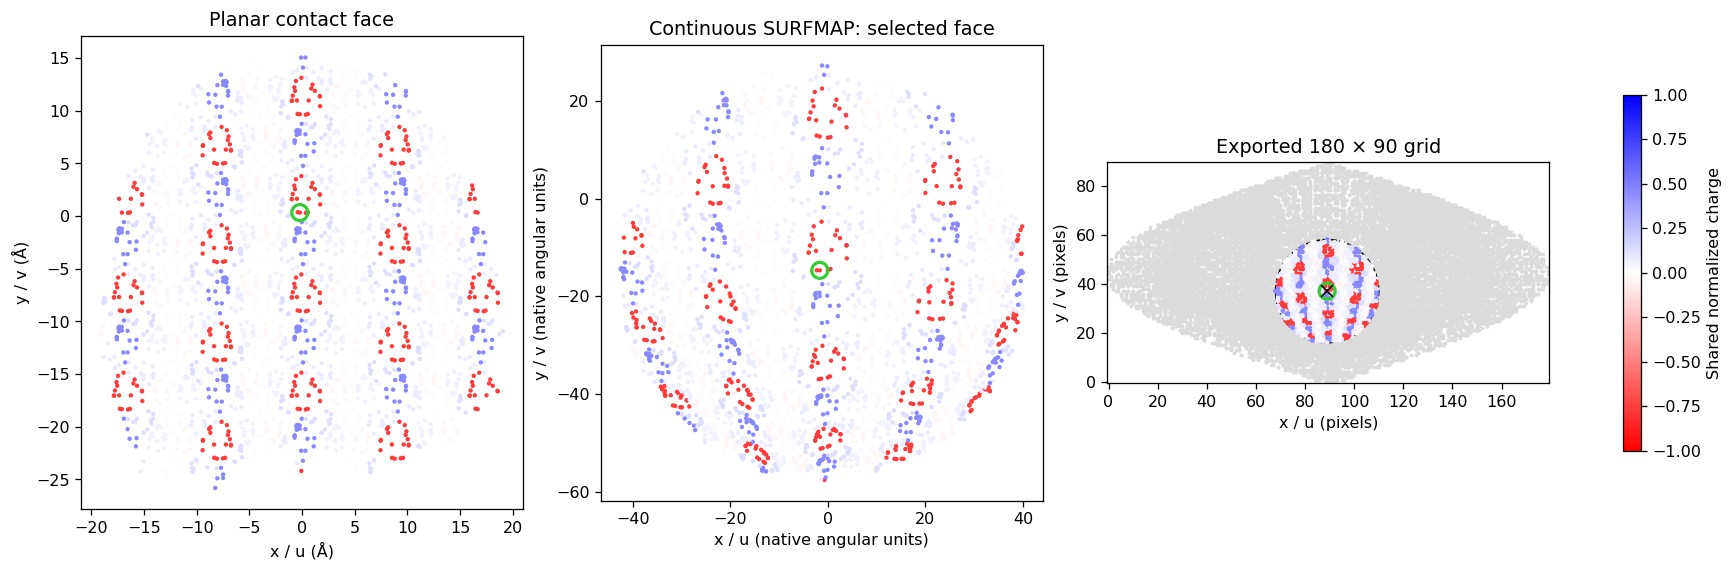

In [12]:
if ANALYSIS_READY:
    print('Analysis population:',ANALYSIS_LABEL,'| n =',len(P))
    physical_radius=np.linalg.norm(P,axis=1)
    centre_index=int(np.argmin(physical_radius))
    centre_row=pd.DataFrame([{'point_id':int(ids[centre_index]),'distance_to_plane_origin_A':physical_radius[centre_index],
                             'SURFMAP_column':pixels[centre_index,0],'SURFMAP_row':pixels[centre_index,1],
                             'x_proj':S[centre_index,0],'y_proj':S[centre_index,1]}])
    display(centre_row)
    roi_all=np.linalg.norm(pixels_all-ROI_CENTER_COL_ROW,axis=1)<=ROI_RADIUS_PIXELS
    roi_selected=roi_all[ids]
    print(f'Conditional ROI at {tuple(ROI_CENTER_COL_ROW)}, radius {ROI_RADIUS_PIXELS:g} pixels:')
    print(f'  selected-face points inside: {roi_selected.sum()} / {len(P)} ({100*roi_selected.mean():.2f}%)')
    print(f'  selected-face fraction of all shell points in this ROI: {100*roi_selected.sum()/max(roi_all.sum(),1):.2f}%')
    print('This diagnoses these exports; it does not establish the orientation of other saved PNG/NPY runs.')
    fig,axs=plt.subplots(1,3,figsize=(15,5),layout='constrained')
    for ax,xy,title,units in zip(axs,[P,S,pixels],['Planar contact face','Continuous SURFMAP: selected face','Exported 180 × 90 grid'],['Å','native angular units','pixels']):
        if units=='pixels':
            ax.scatter(pixels_all[:,0],pixels_all[:,1],s=2,c='.86',rasterized=True)
            ax.add_patch(Circle(ROI_CENTER_COL_ROW,ROI_RADIUS_PIXELS,fill=False,color='k',ls='--',lw=1))
            ax.plot(*ROI_CENTER_COL_ROW,'kx',ms=8)
            ax.set_xlim(-.5,179.5);ax.set_ylim(-.5,89.5)
        im=ax.scatter(xy[:,0],xy[:,1],c=q/CHARGE_NORMALIZATION,cmap='bwr_r',vmin=-1,vmax=1,s=3,rasterized=True)
        ax.scatter(*xy[centre_index],s=100,facecolors='none',edgecolors='limegreen',linewidths=2)
        ax.set(title=title,xlabel=f'x / u ({units})',ylabel=f'y / v ({units})');ax.set_aspect('equal')
    fig.colorbar(im,ax=axs,shrink=.65,label='Shared normalized charge');plt.show();plt.close(fig)

else:
    print("Skipped audit-008: the requested opposite-face XYZ are not available.")


,representation,points,RMSE_A,P95_A,NRMS_radius_pct,A_per_native_unit,det_R
0,SURFMAP continuous,2339,2.29714,4.28211,16.42023,0.44558,1.0
1,SURFMAP binned,2339,2.33586,4.37647,16.69703,0.44560,1.0
2,Re-centred control,2339,2.27946,4.22803,16.29388,0.44732,1.0


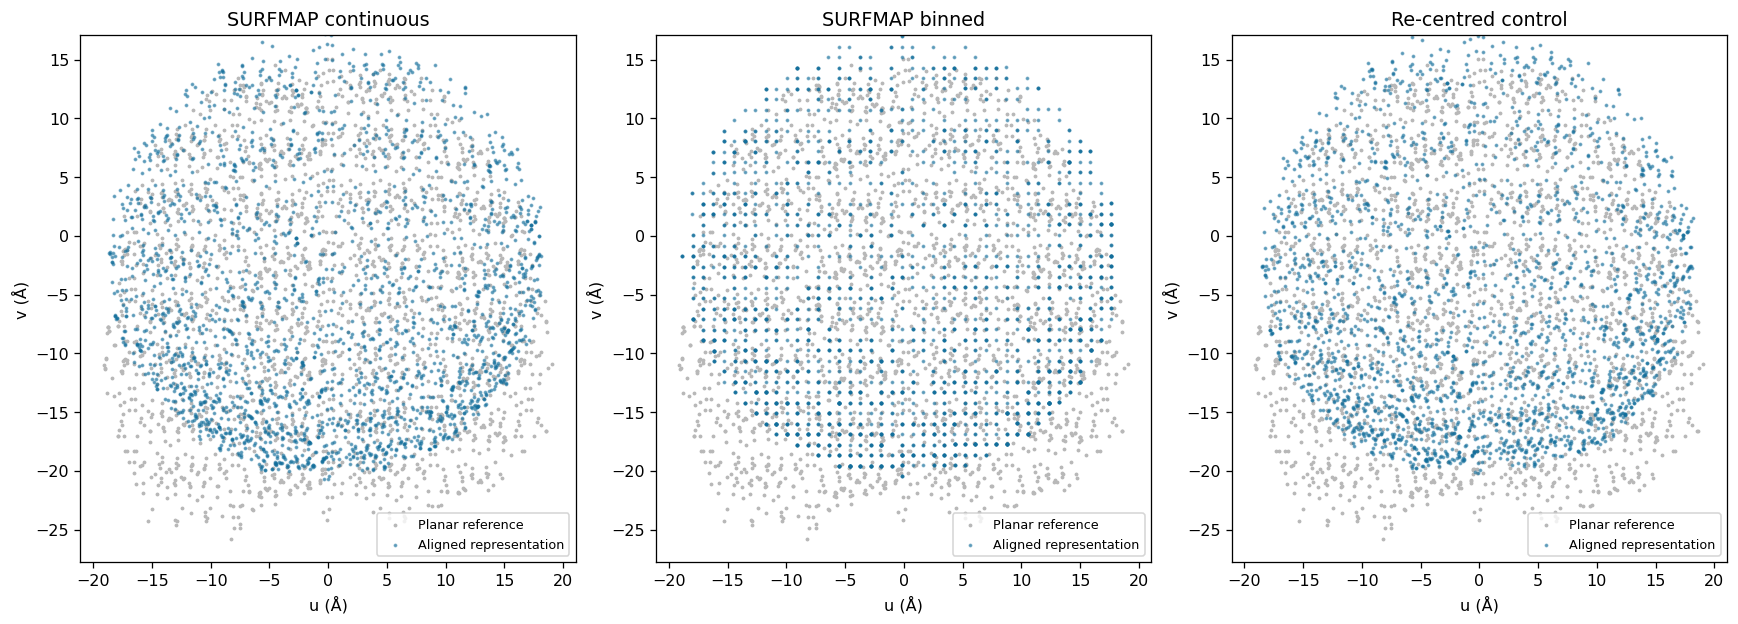

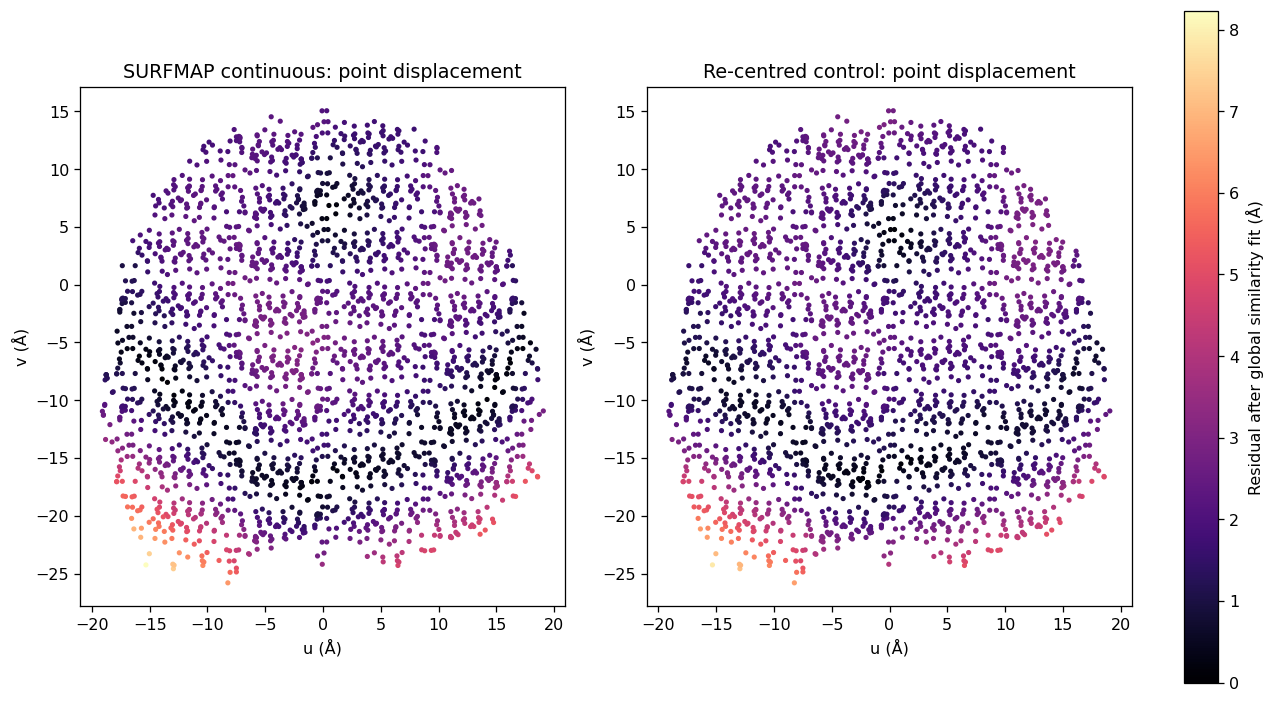

In [21]:
if ANALYSIS_READY:
    def similarity(source,target):
        x0=source-source.mean(0); y0=target-target.mean(0)
        if np.sum(x0*x0)<1e-15: raise ValueError('Degenerate source coordinates.')
        U,_,Vt=np.linalg.svd(x0.T@y0)
        R=U@Vt
        scale=np.sum((x0@R)*y0)/np.sum(x0*x0)
        if scale<=0: raise ValueError('Nonpositive fitted scale.')
        aligned=scale*x0@R+target.mean(0)
        error=np.linalg.norm(aligned-target,axis=1)
        return {'aligned':aligned,'error':error,'scale':scale,'R':R,
                'source_mean':source.mean(0),'target_mean':target.mean(0)}
    def apply_fit(source,fit):
        return (source-fit['source_mean'])@fit['R']*fit['scale']+fit['target_mean']
    fits={name:similarity(xy,P) for name,xy in variants.items()}
    geometry_rows=[]
    for name,fit in fits.items():
        geometry_rows.append({'representation':name,'points':len(P),'RMSE_A':np.sqrt(np.mean(fit['error']**2)),
            'P95_A':np.quantile(fit['error'],.95),'NRMS_radius_pct':100*np.sqrt(np.sum(fit['error']**2)/np.sum((P-P.mean(0))**2)),
            'A_per_native_unit':fit['scale'],'det_R':np.linalg.det(fit['R'])})
    geometry_table=pd.DataFrame(geometry_rows);display(geometry_table.round(5))
    fig,axs=plt.subplots(1,3,figsize=(15,6),layout='constrained')
    for ax,(name,fit) in zip(axs,fits.items()):
        ax.scatter(P[:,0],P[:,1],s=2,color='.72',label='Planar reference')
        ax.scatter(*fit['aligned'].T,s=2,color='#126e9b',alpha=.5,label='Aligned representation')
        idx=np.arange(0,len(P),100)
        # for j in idx: ax.plot([P[j,0],fit['aligned'][j,0]],[P[j,1],fit['aligned'][j,1]],c='#b02b50',lw=.4,alpha=.5)
        ax.set(title=name,xlabel='u (Å)',ylabel='v (Å)',xlim=(P[:,0].min()-2,P[:,0].max()+2),ylim=(P[:,1].min()-2,P[:,1].max()+2));ax.set_aspect('equal');ax.legend(fontsize=8)
    plt.show();plt.close(fig)
    fig,axs=plt.subplots(1,2,figsize=(11,6),layout='constrained')
    for ax,name in zip(axs,['SURFMAP continuous','Re-centred control']):
        im=ax.scatter(*P.T,c=fits[name]['error'],s=5,vmin=0,vmax=max(fits['SURFMAP continuous']['error']),cmap='magma')
        ax.set(title=f'{name}: point displacement',xlabel='u (Å)',ylabel='v (Å)');ax.set_aspect('equal')
    fig.colorbar(im,ax=axs,label='Residual after global similarity fit (Å)');plt.show();plt.close(fig)

else:
    print("Skipped audit-010: the requested opposite-face XYZ are not available.")


Larger-ROI comparison: guard failure is shown, never silently removed.
Fit residuals use each ROI's own points. Fixed-baseline columns use the original (90,45), r=12 calibration.


,centre,column,row,radius_px,points,occupied_pixels,nominal_pixels,occupancy_pct,forbidden_points,forbidden_pct,...,Continuous_RMSE_A,Continuous_P95_A,Continuous_scale,Continuous_NRMS_pct,Continuous_fixed_baseline_RMSE_A,Binned_RMSE_A,Binned_P95_A,Binned_scale,Binned_NRMS_pct,Binned_fixed_baseline_RMSE_A
0,Original,90.0,45.0,12.0,436,267,441,60.5442,0,0.0000,...,0.1567,0.2597,0.3453,2.6301,0.1567,0.3413,0.5179,0.3454,5.7303,0.3413
1,Original,90.0,45.0,15.0,726,447,709,63.0465,23,3.1680,...,0.2811,0.5108,0.3557,3.6238,0.3606,0.4172,0.6706,0.3555,5.3787,0.4722
2,Original,90.0,45.0,18.0,1179,665,1009,65.9068,141,11.9593,...,0.4675,0.8179,0.3697,4.7292,0.8040,0.5743,0.9720,0.3699,5.8096,0.8721
3,Original,90.0,45.0,19.0,1387,762,1129,67.4934,188,13.5544,...,0.5442,0.9387,0.3755,5.0791,1.0190,0.6443,1.0731,0.3758,6.0135,1.0810
4,Original,90.0,45.0,20.0,1644,869,1257,69.1329,277,16.8491,...,0.6699,1.1594,0.3831,5.7467,1.3315,0.7568,1.2968,0.3833,6.4923,1.3796
5,Original,90.0,45.0,21.0,1877,973,1373,70.8667,364,19.3926,...,0.7851,1.3477,0.3897,6.3086,1.6221,0.8652,1.4822,0.3899,6.9522,1.6639
6,Original,90.0,45.0,25.0,3264,1489,1961,75.9306,783,23.9890,...,1.5922,2.7932,0.4264,9.6295,3.5241,1.6417,2.8619,0.4265,9.9290,3.5468
7,Original,90.0,45.0,30.0,6835,2275,2821,80.6452,2294,33.5625,...,3.9633,7.4709,0.5021,16.3739,8.7391,4.0071,7.5401,0.5023,16.5549,8.7605
8,Shifted,89.0,37.0,12.0,489,277,441,62.8118,0,0.0000,...,0.4345,0.7760,0.3694,6.8642,0.7039,0.5454,0.8911,0.3690,8.6169,0.7788
9,Shifted,89.0,37.0,15.0,864,473,709,66.7137,0,0.0000,...,0.7972,1.3797,0.3871,9.4381,1.4543,0.8670,1.4912,0.3868,10.2655,1.4897


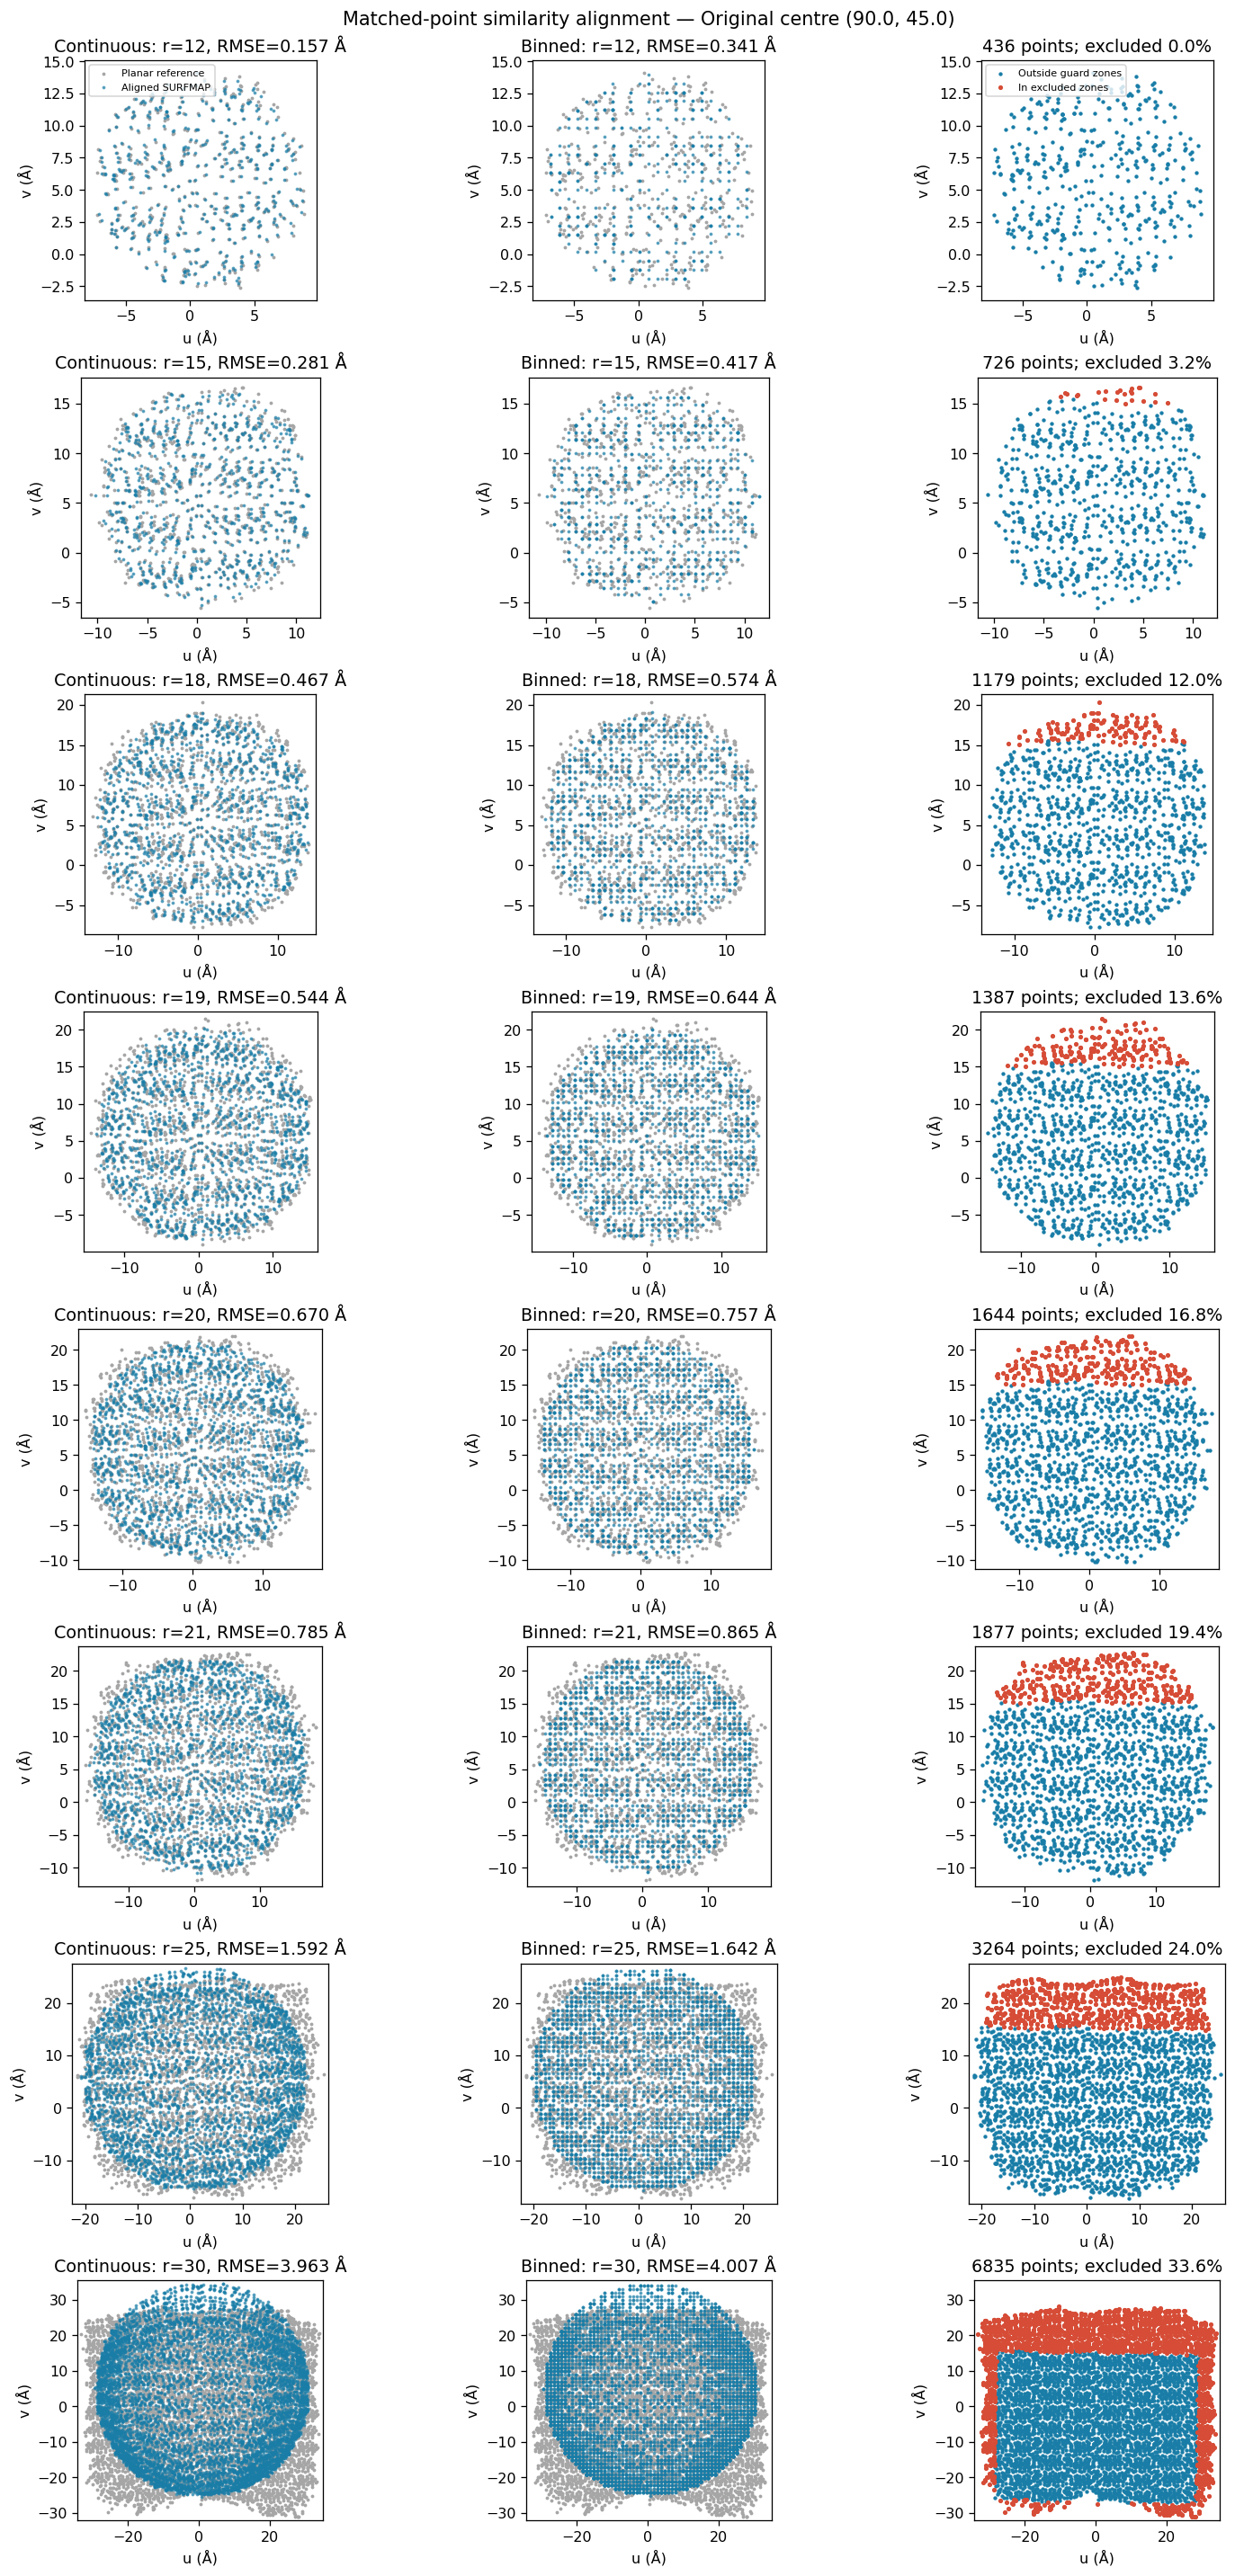

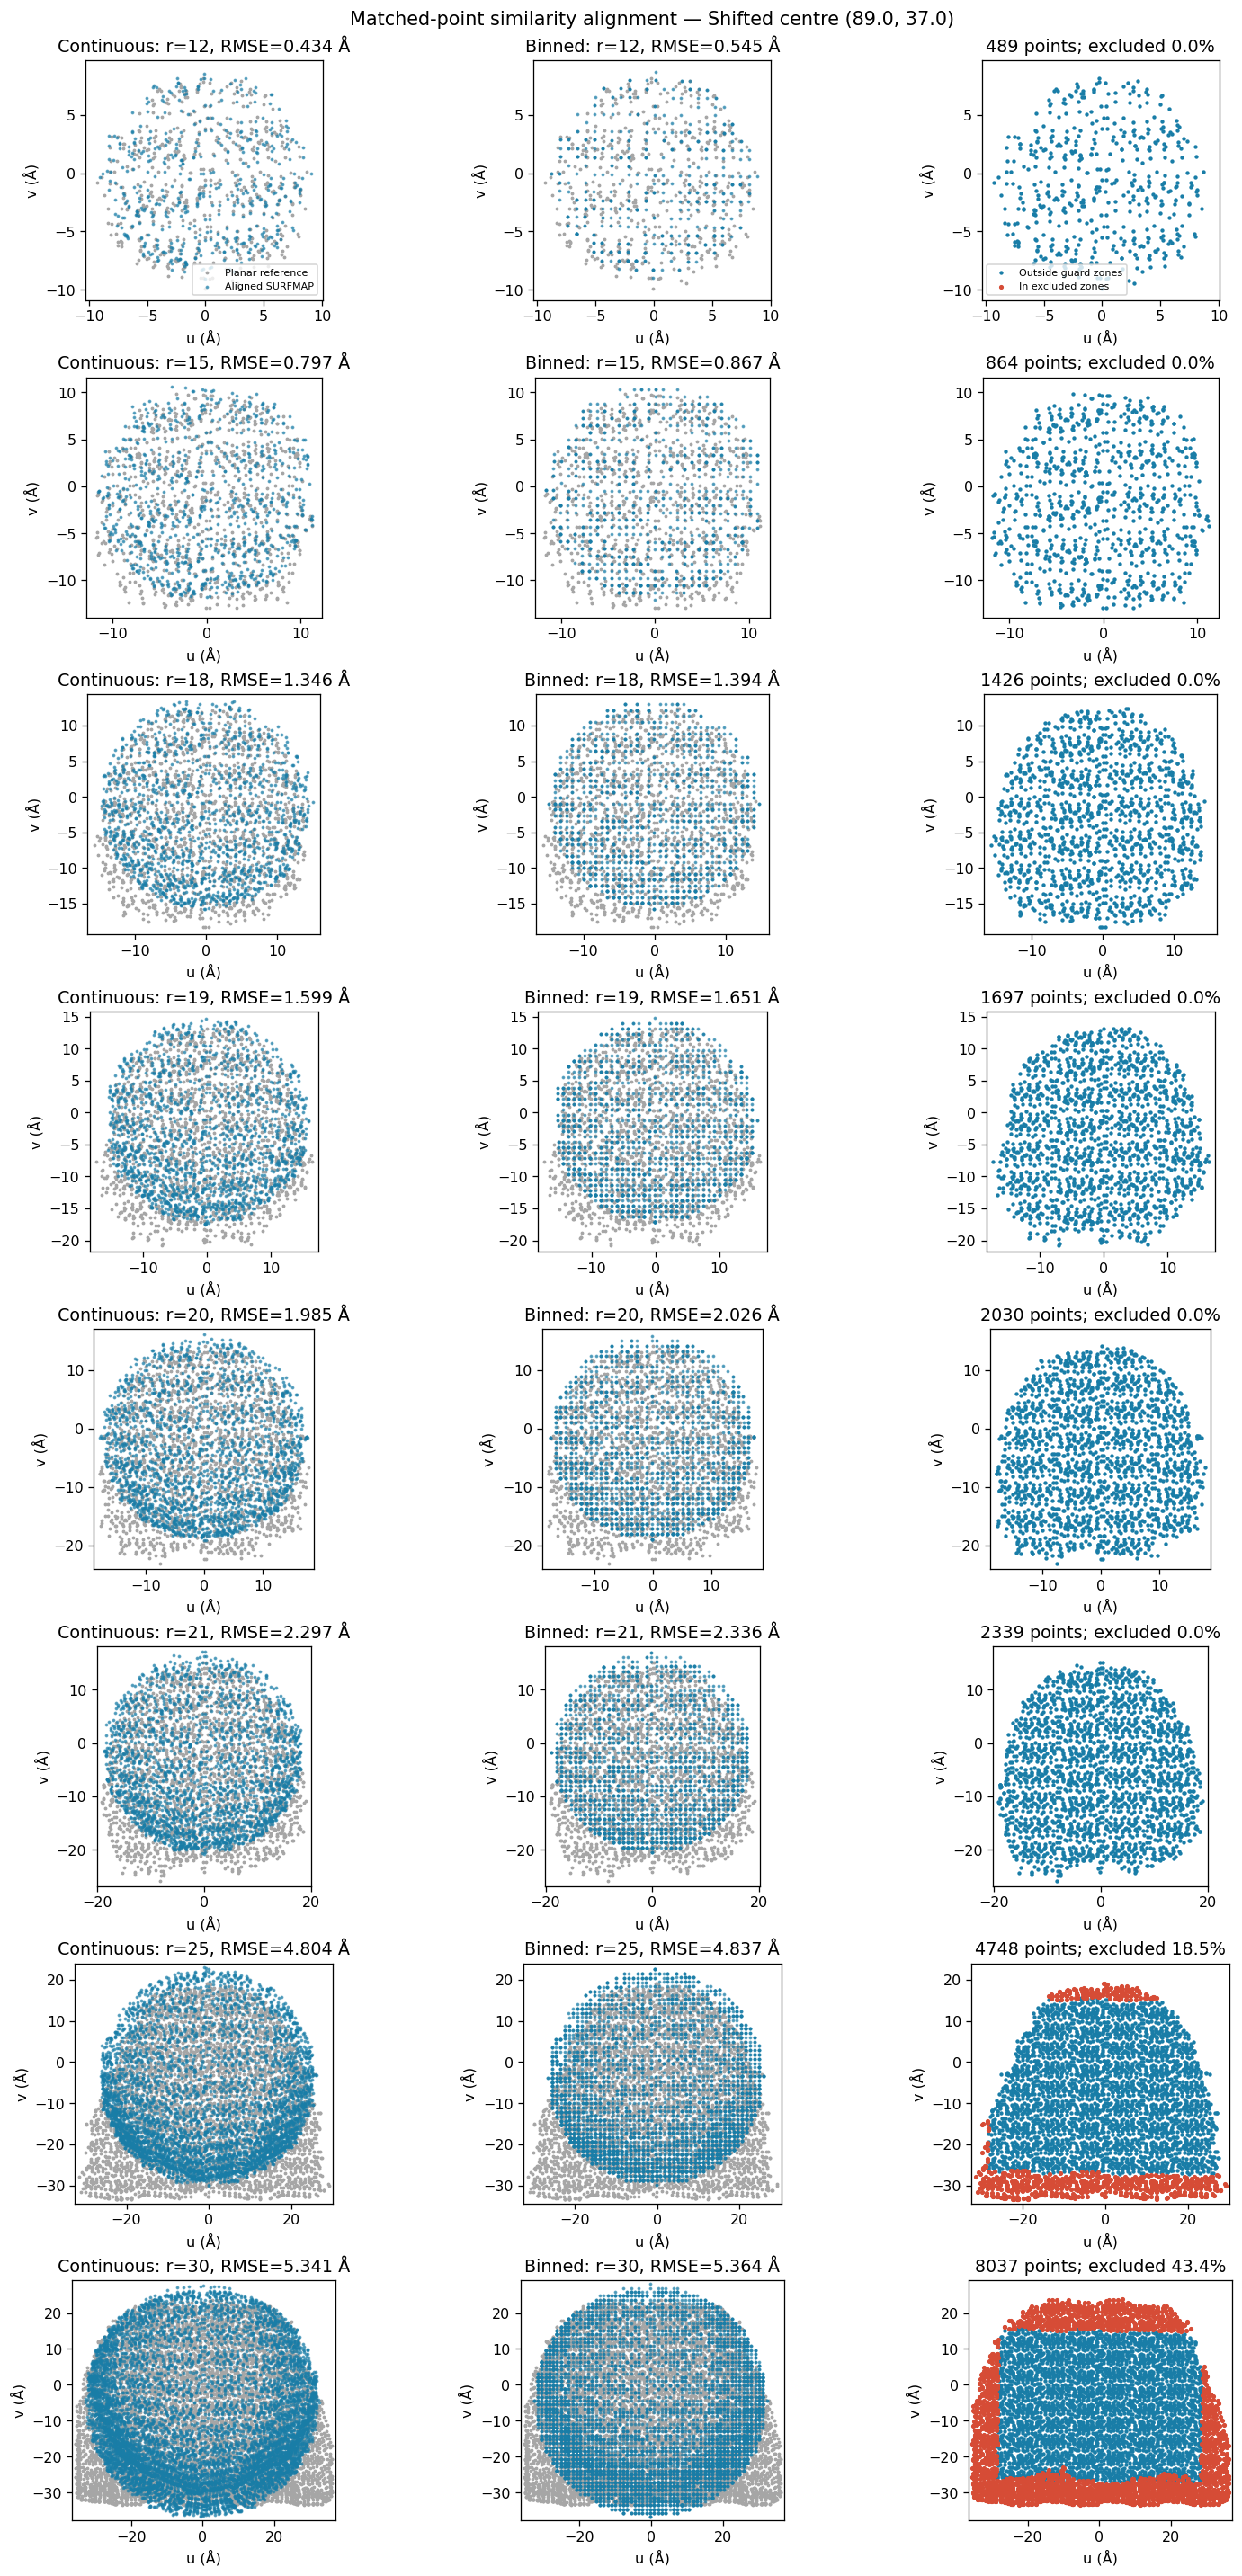

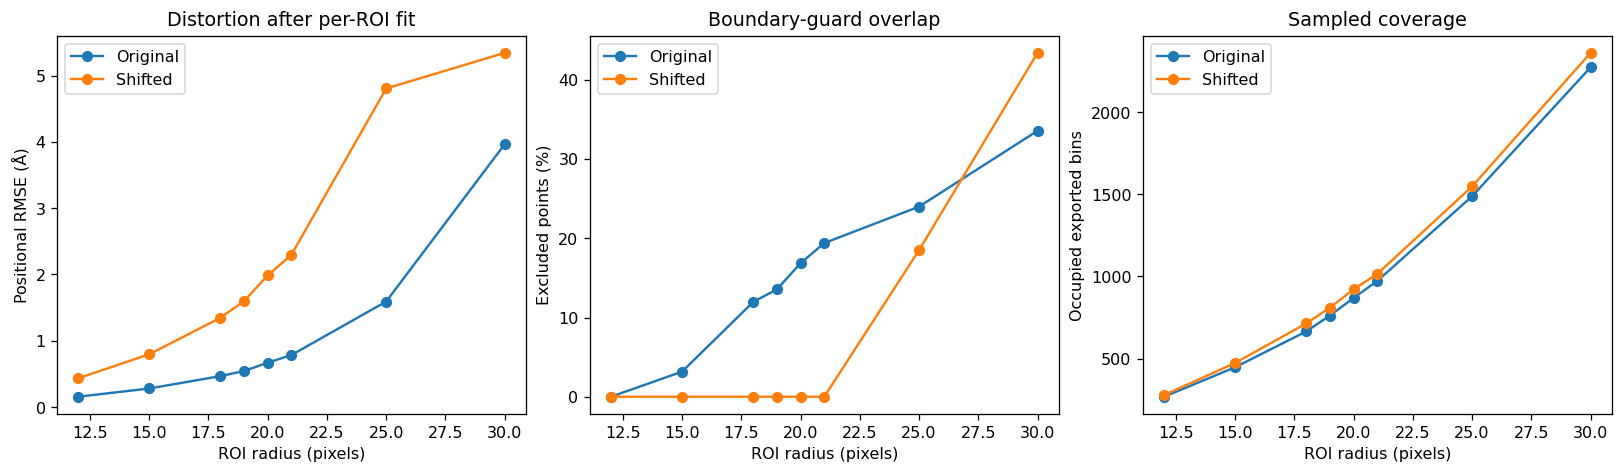

Radius satisfying the guard at all nine tested +/-1 pixel centres: 19.0


In [24]:
if ANALYSIS_READY and FACE_MODE=='surfmap_roi':
    # Keep the physical plane normal fixed for all centres and radii.
    # Every fit uses the exact point population assigned to that ROI's bins.
    full_plane_uv=roi_selection['uv_all']
    full_depth=roi_selection['side_depth_all']
    center_names={'Original':ROI_BASELINE_CENTER_COL_ROW,'Shifted':ROI_CENTER_COL_ROW}
    comparison_rows=[];comparison_payload={}
    for label,center in center_names.items():
        radii=sorted(set(ROI_COMPARISON_RADII+[float(ROI_RADIUS_PIXELS)]))
        for r in radii:
            mask=np.linalg.norm(pixels_all-center,axis=1)<=r
            ii=np.flatnonzero(mask);target=full_plane_uv[ii]
            if len(ii)<10:continue
            forbidden=~center_search['safe'][ii]
            ygrid,xgrid=np.indices(MAP_SHAPE)
            nominal=int((np.hypot(xgrid-center[0],ygrid-center[1])<=r).sum())
            occupied=len(np.unique(pixels_all[ii],axis=0))
            row={'centre':label,'column':float(center[0]),'row':float(center[1]),'radius_px':r,
                 'points':len(ii),'occupied_pixels':occupied,'nominal_pixels':nominal,
                 'occupancy_pct':100*occupied/nominal,
                 'forbidden_points':int(forbidden.sum()),'forbidden_pct':100*forbidden.mean(),
                 'guard_pass':bool(not forbidden.any()),
                 'max_inward_depth_A':float(full_depth[ii].max()),
                 'u_span_A':float(np.ptp(target[:,0])),'v_span_A':float(np.ptp(target[:,1]))}
            payload={'ids':ii,'target':target,'forbidden':forbidden,'fits':{}}
            for name,xy in [('Continuous',full_S[ii]),('Binned',full_B[ii])]:
                f=similarity(xy,target);payload['fits'][name]=f
                row[name+'_RMSE_A']=float(np.sqrt(np.mean(f['error']**2)))
                row[name+'_P95_A']=float(np.quantile(f['error'],.95))
                row[name+'_scale']=float(f['scale'])
                row[name+'_NRMS_pct']=float(100*np.sqrt(np.sum(f['error']**2)/np.sum((target-target.mean(0))**2)))
                # Compare the fit against the fixed original r=12 calibration.
                base_mask=np.linalg.norm(pixels_all-ROI_BASELINE_CENTER_COL_ROW,axis=1)<=12.
                base_xy=full_S if name=='Continuous' else full_B
                base_fit=similarity(base_xy[base_mask],full_plane_uv[base_mask])
                fixed=apply_fit(xy,base_fit)
                row[name+'_fixed_baseline_RMSE_A']=float(np.sqrt(np.mean(np.sum((fixed-target)**2,axis=1))))
            comparison_payload[(label,r)]=payload;comparison_rows.append(row)
    multi_roi_table=pd.DataFrame(comparison_rows)
    print('Larger-ROI comparison: guard failure is shown, never silently removed.')
    print('Fit residuals use each ROI\'s own points. Fixed-baseline columns use the original (90,45), r=12 calibration.')
    display(multi_roi_table.round(4))
    for label,center in center_names.items():
        keys=[k for k in comparison_payload if k[0]==label]
        fig,axs=plt.subplots(len(keys),3,figsize=(13,3.1*len(keys)),layout='constrained',squeeze=False)
        for axsrow,key in zip(axs,keys):
            p=comparison_payload[key];target=p['target'];bad=p['forbidden']
            radius=key[1];row=multi_roi_table[(multi_roi_table.centre==label)&(multi_roi_table.radius_px==radius)].iloc[0]
            # Each row's limits are shared between all representations.
            lim=np.vstack([target]+[f['aligned'] for f in p['fits'].values()])
            xlim=(lim[:,0].min()-1,lim[:,0].max()+1);ylim=(lim[:,1].min()-1,lim[:,1].max()+1)
            for ax,(name,f) in zip(axsrow[:2],p['fits'].items()):
                ax.scatter(*target.T,s=2,c='.65',label='Planar reference',rasterized=True)
                ax.scatter(*f['aligned'].T,s=2,c='#197da7',alpha=.6,label='Aligned SURFMAP',rasterized=True)
                ax.set(title=f'{name}: r={radius:g}, RMSE={row[name+"_RMSE_A"]:.3f} Å',
                       xlabel='u (Å)',ylabel='v (Å)',xlim=xlim,ylim=ylim);ax.set_aspect('equal')
            ax=axsrow[2]
            ax.scatter(*target[~bad].T,s=3,c='#197da7',label='Outside guard zones',rasterized=True)
            ax.scatter(*target[bad].T,s=5,c='#d64c36',label='In excluded zones',rasterized=True)
            ax.set(title=f'{len(target)} points; excluded {100*bad.mean():.1f}%',xlabel='u (Å)',ylabel='v (Å)',xlim=xlim,ylim=ylim);ax.set_aspect('equal')
        axs[0,0].legend(fontsize=7);axs[0,2].legend(fontsize=7)
        fig.suptitle(f'Matched-point similarity alignment — {label} centre {tuple(center)}',fontsize=13)
        plt.show();plt.close(fig)
    fig,axs=plt.subplots(1,3,figsize=(14,4),layout='constrained')
    for label,g in multi_roi_table.groupby('centre',sort=False):
        axs[0].plot(g.radius_px,g.Continuous_RMSE_A,'o-',label=label)
        axs[1].plot(g.radius_px,g.forbidden_pct,'o-',label=label)
        axs[2].plot(g.radius_px,g.occupied_pixels,'o-',label=label)
    for ax,title,y in zip(axs,['Distortion after per-ROI fit','Boundary-guard overlap','Sampled coverage'],
                          ['Positional RMSE (Å)','Excluded points (%)','Occupied exported bins']):
        ax.set(title=title,xlabel='ROI radius (pixels)',ylabel=y);ax.legend()
    plt.show();plt.close(fig)
    # Local centre perturbation: a discrete optimum can sit close to a boundary.
    perturb=[]
    for dx in [-1,0,1]:
        for dy in [-1,0,1]:
            c=ROI_CENTER_COL_ROW+[dx,dy]
            m=np.linalg.norm(pixels_all-c,axis=1)<=ROI_RADIUS_PIXELS
            bad=int(np.sum(m&~center_search['safe']))
            d=cKDTree(np.unique(pixels_all[~center_search['safe']],axis=0)).query(c)[0]
            perturb.append({'column':c[0],'row':c[1],'radius_px':ROI_RADIUS_PIXELS,
                            'points':int(m.sum()),'forbidden_points':bad,
                            'max_radius_without_forbidden_px':min(float(np.ceil(d-1e-9)-1),float(ROI_CANDIDATE_RADII.max()))})
    center_perturbation_table=pd.DataFrame(perturb)
    robust_radius=min(center_perturbation_table.max_radius_without_forbidden_px)
    print('Radius satisfying the guard at all nine tested +/-1 pixel centres:',robust_radius)
    if SAVE_TABLES:
        OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
        multi_roi_table.to_csv(OUTPUT_DIR/'multi_roi_similarity.csv',index=False)
        center_comparison_table.to_csv(OUTPUT_DIR/'roi_center_comparison.csv',index=False)
        center_search['search'].to_csv(OUTPUT_DIR/'roi_center_search.csv',index=False)
        center_perturbation_table.to_csv(OUTPUT_DIR/'roi_center_perturbation.csv',index=False)


In [16]:
if ANALYSIS_READY and SHELL_PDB is not None and FACE_MODE=='opposite_face':
    view_outward=np.array([1.,0.,0.])@rotation3.T
    central_candidate=select_parallel_face(xyz_shell,view_outward,source_basis[2],float(source_plane.depth_A.max()))
    face_overview=[]
    for label,face in [('Source CSV face',source_check),('Opposite parallel face',opposite),
                       ('Map-centre-directed slab (diagnostic)',central_candidate)]:
        ii=face['ids'];xy=projected.iloc[ii][['x_proj','y_proj']].to_numpy()
        fitting=similarity(xy,face['uv'])
        idx0=int(np.argmin(np.linalg.norm(face['uv'],axis=1)))
        centre_id=int(ii[idx0]);pix=pixels_all[ii]
        roi=np.linalg.norm(pix-ROI_CENTER_COL_ROW,axis=1)<=ROI_RADIUS_PIXELS
        face_overview.append({'selection':label,'points':len(ii),'nearest_centre_point_id':centre_id,
            'centre_column':pixels_all[centre_id,0],'centre_row':pixels_all[centre_id,1],
            'in_pixel_ROI_pct':100*roi.mean(),'continuous_RMSE_A':np.sqrt(np.mean(fitting['error']**2)),
            'outward_vs_map_centre_deg':np.rad2deg(np.arccos(np.clip(face['outward_normal']@view_outward,-1,1)))})
    face_overview_table=pd.DataFrame(face_overview);display(face_overview_table.round(4))


,representation,radius_A,points,local_fit_RMSE_A,local_fit_P95_A,local_NRMS_radius_pct,local_scale,global_fit_RMSE_A
0,SURFMAP continuous,5,158,0.1364,0.2099,3.8616,0.3499,2.1655
1,SURFMAP binned,5,158,0.3165,0.4811,8.9627,0.3450,2.2228
2,Re-centred control,5,158,0.1402,0.2223,3.9697,0.3500,1.7014
3,SURFMAP continuous,10,610,0.4492,0.8436,6.3996,0.3663,2.1799
4,SURFMAP binned,10,610,0.5519,0.9257,7.8620,0.3653,2.2162
5,Re-centred control,10,610,0.4535,0.8074,6.4600,0.3666,1.9395
6,SURFMAP continuous,15,1354,0.8301,1.5215,7.8714,0.3854,2.0727
7,SURFMAP binned,15,1354,0.8898,1.5572,8.4371,0.3852,2.1073
8,Re-centred control,15,1354,0.8769,1.5442,8.3145,0.3861,2.0311
9,SURFMAP continuous,20,1910,1.4716,2.6876,11.7238,0.4148,1.8506


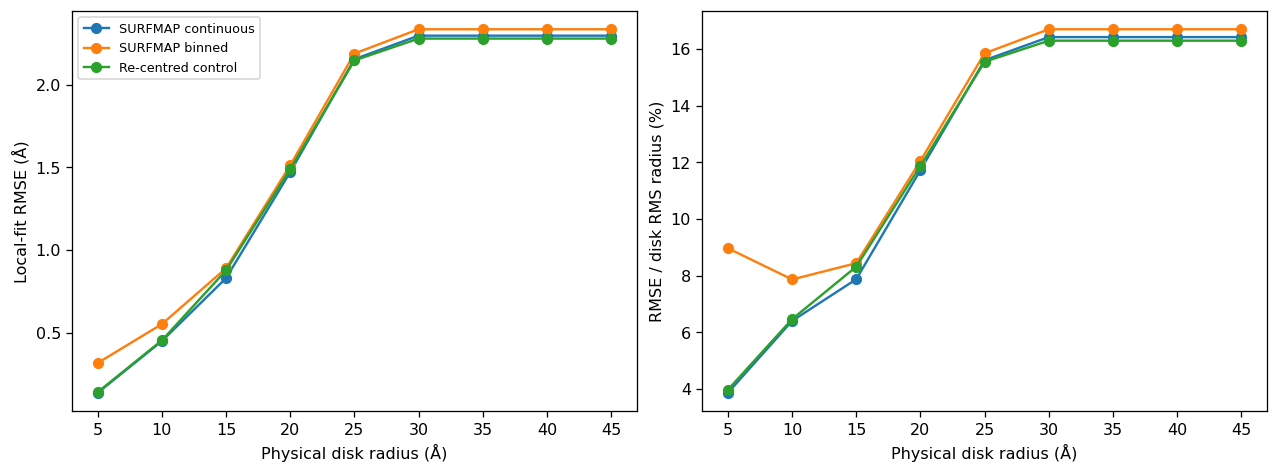

In [17]:
if ANALYSIS_READY:
    central_rows=[]
    for radius in CENTRAL_RADII_A:
        mask=physical_radius<=radius
        if mask.sum()<10: continue
        for name,xy in variants.items():
            local=similarity(xy[mask],P[mask])
            rms=np.sqrt(np.mean(local['error']**2))
            spread=np.sqrt(np.mean(np.sum((P[mask]-P[mask].mean(0))**2,axis=1)))
            central_rows.append({'representation':name,'radius_A':radius,'points':int(mask.sum()),
              'local_fit_RMSE_A':rms,'local_fit_P95_A':np.quantile(local['error'],.95),
              'local_NRMS_radius_pct':100*rms/spread,'local_scale':local['scale'],
              'global_fit_RMSE_A':np.sqrt(np.mean(fits[name]['error'][mask]**2))})
    central_table=pd.DataFrame(central_rows);display(central_table.round(4))
    fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
    for name,g in central_table.groupby('representation',sort=False):
        axs[0].plot(g.radius_A,g.local_fit_RMSE_A,'o-',label=name)
        axs[1].plot(g.radius_A,g.local_NRMS_radius_pct,'o-',label=name)
    axs[0].set(xlabel='Physical disk radius (Å)',ylabel='Local-fit RMSE (Å)')
    axs[1].set(xlabel='Physical disk radius (Å)',ylabel='RMSE / disk RMS radius (%)')
    axs[0].legend(fontsize=8);plt.show();plt.close(fig)

else:
    print("Skipped audit-012: the requested opposite-face XYZ are not available.")


All unique planar pairs up to the maximum band: 1080001
Max discrepancy in d3D² = dplane² + Δdepth²: 2.793772158060648e-13


,representation,band_A,pairs,median_ratio,median_abs_error_pct,P95_abs_error_pct,collapsed_pct,original_seam_pairs_pct,median_abs_error_no_seam_pct,same_depth_pairs,median_abs_error_depth_le_0_5_pct,plane_vs_3D_median_abs_error_pct,map_vs_3D_median_abs_error_pct
0,SURFMAP continuous,0–0.5,1898,0.975,21.338,59.046,0.000,0.0,21.338,1864,21.330,1.347,20.520
1,SURFMAP continuous,0.5–1,4939,0.993,20.241,53.625,0.000,0.0,20.241,4700,20.293,0.308,19.679
2,SURFMAP continuous,1–2,20852,0.993,18.841,51.247,0.000,0.0,18.841,18315,18.658,0.134,18.467
3,SURFMAP continuous,2–5,129037,0.999,18.836,47.581,0.000,0.0,18.836,97128,18.997,0.097,18.589
4,SURFMAP continuous,5–10,397579,1.011,17.959,43.086,0.000,0.0,17.959,196255,18.917,0.237,17.835
5,SURFMAP continuous,10–15,525696,1.014,16.248,37.106,0.000,0.0,16.248,235019,16.255,0.114,16.183
6,SURFMAP binned,0–0.5,1898,0.000,100.000,308.333,63.962,0.0,100.000,1864,100.000,1.347,100.000
7,SURFMAP binned,0.5–1,4939,1.082,38.851,100.000,20.854,0.0,38.851,4700,40.257,0.308,36.329
8,SURFMAP binned,1–2,20852,1.017,25.799,66.226,2.772,0.0,25.799,18315,25.690,0.134,25.462
9,SURFMAP binned,2–5,129037,0.994,19.208,52.040,0.052,0.0,19.208,97128,19.364,0.097,19.020


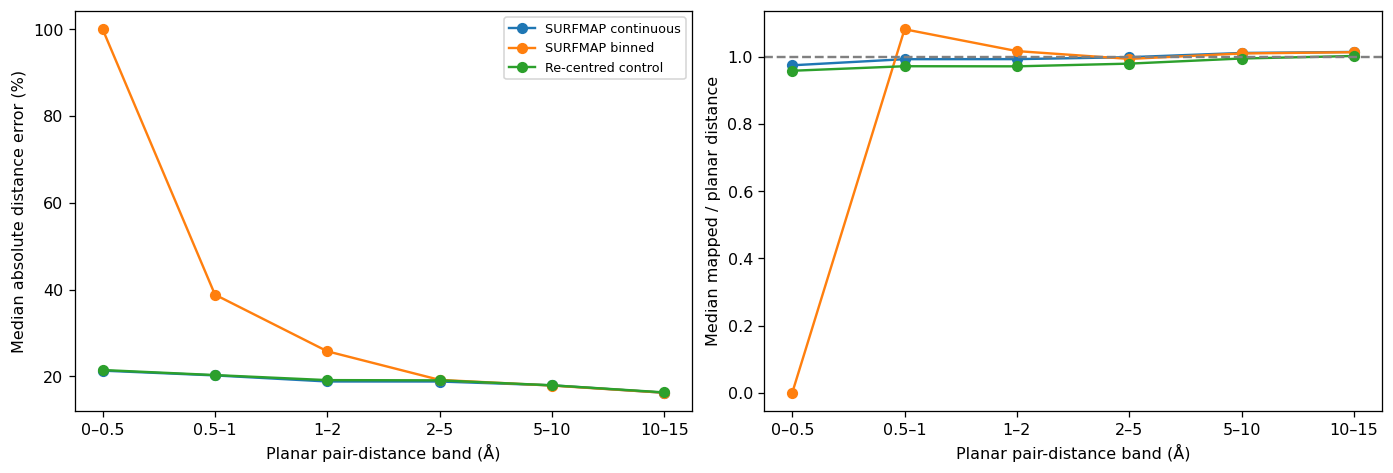

In [18]:
if ANALYSIS_READY:
    max_distance=max(b for a,b in DISTANCE_BANDS_A)
    edges=cKDTree(P).query_pairs(max_distance,output_type='ndarray').astype(np.int32)
    i,j=edges.T
    dp=np.linalg.norm(P[i]-P[j],axis=1)
    d3=np.linalg.norm(XYZ[i]-XYZ[j],axis=1)
    ddepth=np.abs(plane.depth_A.to_numpy()[i]-plane.depth_A.to_numpy()[j])
    seam=np.abs(longitude[i]-longitude[j])>np.pi
    print('All unique planar pairs up to the maximum band:',len(edges))
    print('Max discrepancy in d3D² = dplane² + Δdepth²:',np.max(np.abs(d3*d3-dp*dp-ddepth*ddepth)))
    pair_rows=[]
    for name,fit in fits.items():
        dm=np.linalg.norm(fit['aligned'][i]-fit['aligned'][j],axis=1)
        for lo,hi in DISTANCE_BANDS_A:
            mask=(dp>max(lo,1e-10))&(dp<=hi)
            if not mask.any(): continue
            ratio=dm[mask]/dp[mask]; err=100*np.abs(ratio-1)
            same_depth=mask&(ddepth<=.5)
            no_seam=mask&~seam
            pair_rows.append({'representation':name,'band_A':f'{lo:g}–{hi:g}', 'pairs':int(mask.sum()),
              'median_ratio':np.median(ratio),'median_abs_error_pct':np.median(err),'P95_abs_error_pct':np.quantile(err,.95),
              'collapsed_pct':100*np.mean(dm[mask]<1e-10),'original_seam_pairs_pct':100*np.mean(seam[mask]),
              'median_abs_error_no_seam_pct':np.median(100*np.abs(dm[no_seam]/dp[no_seam]-1)) if no_seam.any() else np.nan,
              'same_depth_pairs':int(same_depth.sum()),
              'median_abs_error_depth_le_0_5_pct':np.median(100*np.abs(dm[same_depth]/dp[same_depth]-1)) if same_depth.any() else np.nan,
              'plane_vs_3D_median_abs_error_pct':np.median(100*np.abs(dp[mask]/d3[mask]-1)),
              'map_vs_3D_median_abs_error_pct':np.median(100*np.abs(dm[mask]/d3[mask]-1))})
        del dm
    pair_table=pd.DataFrame(pair_rows);display(pair_table.round(3))
    fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
    for name,g in pair_table.groupby('representation',sort=False):
        axs[0].plot(g.band_A,g.median_abs_error_pct,'o-',label=name)
        axs[1].plot(g.band_A,g.median_ratio,'o-',label=name)
    axs[0].set(xlabel='Planar pair-distance band (Å)',ylabel='Median absolute distance error (%)')
    axs[1].set(xlabel='Planar pair-distance band (Å)',ylabel='Median mapped / planar distance');axs[1].axhline(1,c='.5',ls='--')
    axs[0].legend(fontsize=8);plt.show();plt.close(fig)
    del edges,i,j,dp,d3,ddepth,seam

else:
    print("Skipped audit-014: the requested opposite-face XYZ are not available.")


In [19]:
if ANALYSIS_READY:
    front=pd.DataFrame({'column':pixels[:,0].astype(int),'row':pixels[:,1].astype(int),'q':q})
    groups=front.groupby(['column','row'])
    counts=groups.size();q_mean=groups.q.transform('mean').to_numpy()
    aggregation_table=pd.DataFrame([{'selected_points':len(P),'occupied_cells':len(counts),
        'points_in_shared_cells_pct':100*counts[counts>1].sum()/len(P),'max_points_per_cell':int(counts.max()),
        'point_weighted_raw_charge_RMSE':np.sqrt(np.mean((q_mean-q)**2)),
        'strict_sign_reversal_pct':100*np.mean(q_mean*q<0),
        'point_weighted_charge_Pearson_r':pearsonr(q_mean,q).statistic}])
    display(aggregation_table.round(5))

else:
    print("Skipped audit-016: the requested opposite-face XYZ are not available.")


,selected_points,occupied_cells,points_in_shared_cells_pct,max_points_per_cell,point_weighted_raw_charge_RMSE,strict_sign_reversal_pct,point_weighted_charge_Pearson_r
0,2339,1016,81.74434,13,0.08426,5.98546,0.94521


,representation,sigma_A,common_cells,support_IoU,plane_support_covered_pct,Pearson_r,Spearman_rho,RMSE,reference_std,mapped_std,both_significant_pct,sign_agreement_pct
0,SURFMAP continuous,0.5,4391,0.7618,82.1669,0.3797,0.3415,0.3242,0.2904,0.2909,44.1813,72.2680
1,SURFMAP binned,0.5,4363,0.7612,81.6430,0.3847,0.3416,0.3184,0.2907,0.2825,44.7169,72.7319
2,Re-centred control,0.5,4411,0.7629,82.5412,0.4023,0.3656,0.3191,0.2901,0.2927,43.5275,74.7396
3,SURFMAP continuous,1.0,4863,0.7775,83.5567,0.5012,0.5021,0.2044,0.2047,0.2031,42.3607,80.1942
4,SURFMAP binned,1.0,4843,0.7764,83.2131,0.5191,0.5144,0.1986,0.2048,0.1986,42.4530,80.7879
5,Re-centred control,1.0,4866,0.7766,83.6082,0.5044,0.5170,0.2047,0.2048,0.2049,41.9647,82.0764
6,SURFMAP continuous,2.0,5818,0.8104,86.4487,0.6993,0.6716,0.0764,0.1016,0.0937,32.6573,94.0526
7,SURFMAP binned,2.0,5815,0.8107,86.4042,0.7113,0.6761,0.0748,0.1016,0.0934,32.9665,93.8967
8,Re-centred control,2.0,5828,0.8102,86.5973,0.6591,0.6486,0.0817,0.1022,0.0943,32.0865,93.4759
9,SURFMAP continuous,3.0,6830,0.8376,88.7359,0.8220,0.7232,0.0313,0.0547,0.0479,16.1933,100.0000


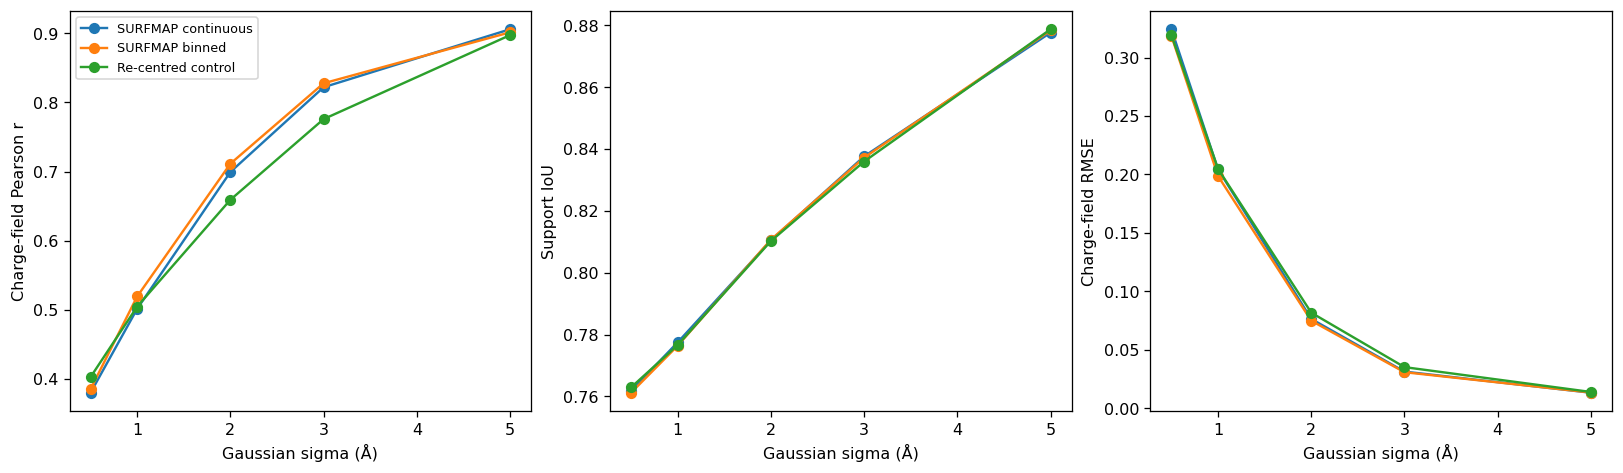

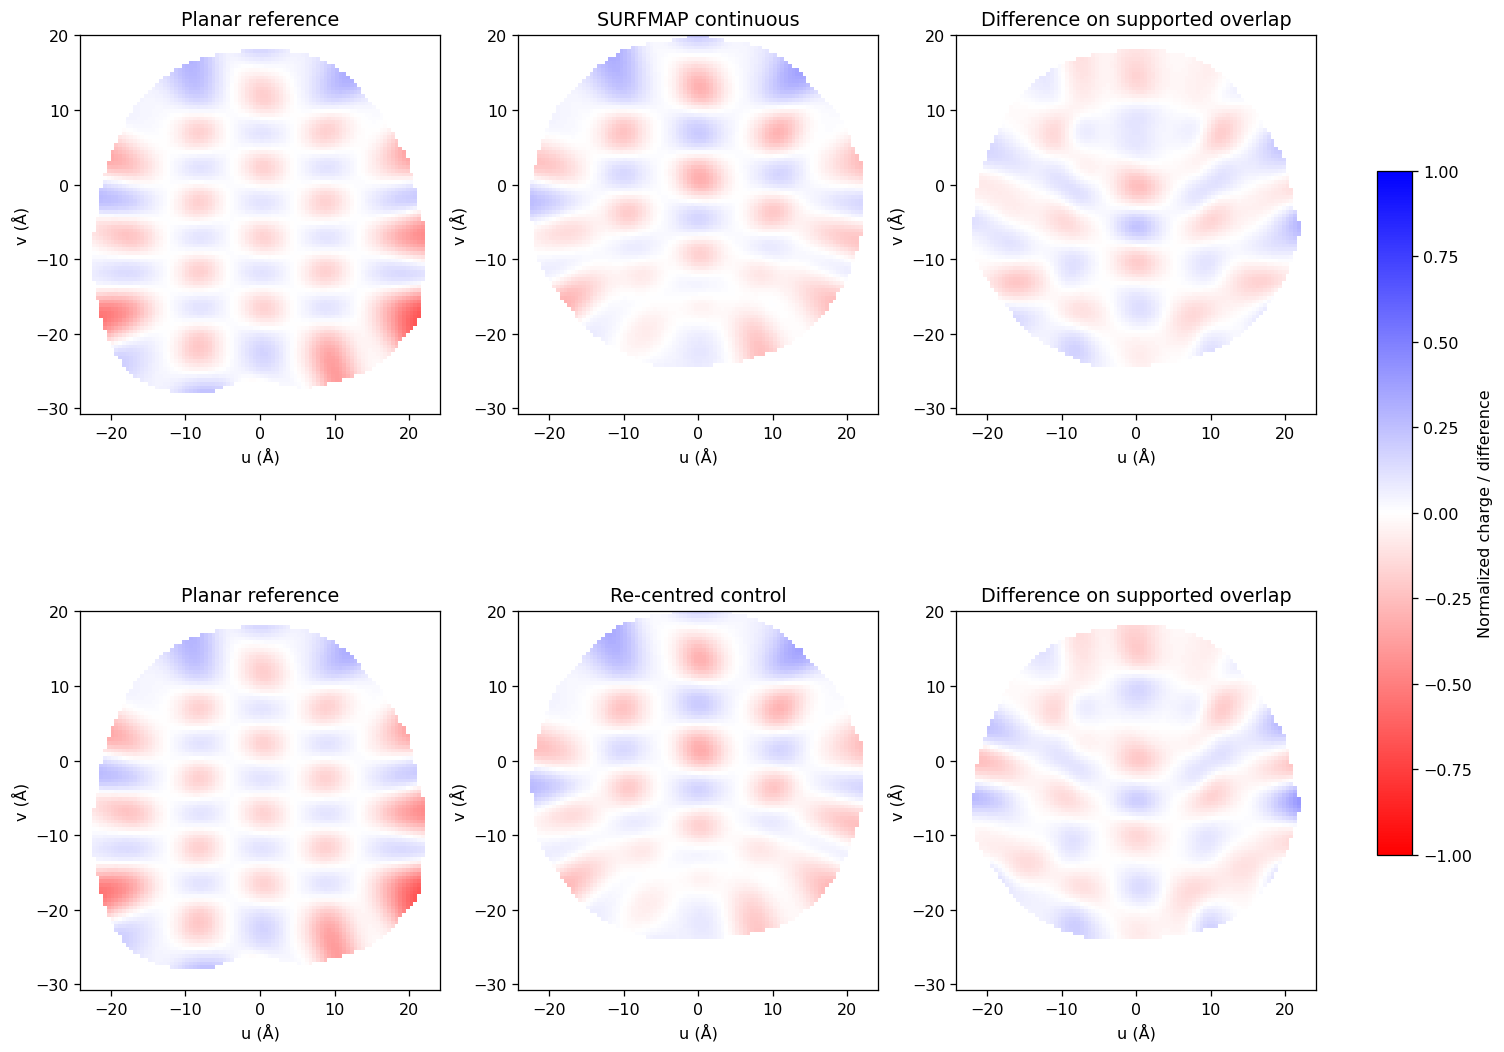

In [20]:
if ANALYSIS_READY:
    q_norm=q/CHARGE_NORMALIZATION
    if np.max(np.abs(q_norm))>1+1e-8: raise ValueError('Charge normalization is inconsistent with these files.')
    if 'charge_normalized' in plane and not np.allclose(q_norm,plane.charge_normalized,atol=1e-8):
        raise ValueError('The configured charge normalization differs from the supplied CSV.')
    step=CHARGE_GRID_STEP_A
    padding=4*max(SMOOTHING_SIGMA_A)+step
    all_locations=np.vstack([P]+[f['aligned'] for f in fits.values()])
    origin=np.floor((all_locations.min(0)-padding)/step)*step
    end=np.ceil((all_locations.max(0)+padding)/step)*step
    shape_xy=np.ceil((end-origin)/step).astype(int)
    if np.prod(shape_xy)>5_000_000: raise ValueError('Charge grid too large; increase CHARGE_GRID_STEP_A.')
    def raster(xy):
        ij=np.floor((xy-origin)/step).astype(int)
        if (ij<0).any() or (ij>=shape_xy).any(): raise ValueError('Raster bounds exclude input points.')
        sums=np.zeros(tuple(shape_xy[::-1]));count=np.zeros_like(sums)
        np.add.at(sums,(ij[:,1],ij[:,0]),q_norm)
        np.add.at(count,(ij[:,1],ij[:,0]),1)
        assert int(count.sum())==len(P)
        return sums,count
    def field(sums,count,sigma):
        weights=gaussian_filter(count,sigma/step,mode='constant',truncate=4.)
        numerator=gaussian_filter(sums,sigma/step,mode='constant',truncate=4.)
        mask=weights>SUPPORT_THRESHOLD
        out=np.full_like(weights,np.nan);out[mask]=numerator[mask]/weights[mask]
        return out,mask
    rasters={'Planar reference':raster(P)}
    rasters.update({name:raster(f['aligned']) for name,f in fits.items()})
    charge_rows=[];show_fields={}
    for sigma in SMOOTHING_SIGMA_A:
        ref,rm=field(*rasters['Planar reference'],sigma)
        for name in variants:
            other,om=field(*rasters[name],sigma);common=rm&om
            a,b=ref[common],other[common]
            valid=len(a)>2 and np.std(a)>1e-12 and np.std(b)>1e-12
            significant=(np.abs(a)>=SIGN_THRESHOLD)&(np.abs(b)>=SIGN_THRESHOLD)
            charge_rows.append({'representation':name,'sigma_A':sigma,'common_cells':int(common.sum()),
                'support_IoU':common.sum()/max((rm|om).sum(),1),'plane_support_covered_pct':100*common.sum()/max(rm.sum(),1),
                'Pearson_r':pearsonr(a,b).statistic if valid else np.nan,
                'Spearman_rho':spearmanr(a,b).statistic if valid else np.nan,
                'RMSE':np.sqrt(np.mean((a-b)**2)) if len(a) else np.nan,
                'reference_std':np.std(a),'mapped_std':np.std(b),
                'both_significant_pct':100*np.mean(significant) if len(a) else np.nan,
                'sign_agreement_pct':100*np.mean(np.sign(a[significant])==np.sign(b[significant])) if significant.any() else np.nan})
            if sigma==2.: show_fields[name]=(ref.copy(),other.copy(),common.copy())
    charge_table=pd.DataFrame(charge_rows);display(charge_table.round(4))
    fig,axs=plt.subplots(1,3,figsize=(14,4),layout='constrained')
    for name,g in charge_table.groupby('representation',sort=False):
        axs[0].plot(g.sigma_A,g.Pearson_r,'o-',label=name)
        axs[1].plot(g.sigma_A,g.support_IoU,'o-')
        axs[2].plot(g.sigma_A,g.RMSE,'o-')
    for ax,ylabel in zip(axs,['Charge-field Pearson r','Support IoU','Charge-field RMSE']):
        ax.set(xlabel='Gaussian sigma (Å)',ylabel=ylabel)
    axs[0].legend(fontsize=8);plt.show();plt.close(fig)
    if show_fields:
        fig,axs=plt.subplots(2,3,figsize=(13,10),layout='constrained')
        extent=[origin[0],end[0],origin[1],end[1]]
        for row,name in enumerate(['SURFMAP continuous','Re-centred control']):
            ref,other,common=show_fields[name]
            diff=np.where(common,other-ref,np.nan)
            for ax,array,title in zip(axs[row],[ref,other,diff],['Planar reference',name,'Difference on supported overlap']):
                im=ax.imshow(array,origin='lower',extent=extent,cmap='bwr_r',vmin=-1,vmax=1,interpolation='nearest')
                ax.set(title=title,xlabel='u (Å)',ylabel='v (Å)',xlim=(P[:,0].min()-5,P[:,0].max()+5),ylim=(P[:,1].min()-5,P[:,1].max()+5))
        fig.colorbar(im,ax=axs.ravel().tolist(),shrink=.6,label='Normalized charge / difference');plt.show();plt.close(fig)

else:
    print("Skipped audit-018: the requested opposite-face XYZ are not available.")
